# Лабораторная работа №12: Генерация синтетического датасета для VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Сгенерировать спецификации сцен и изображения.
- Проверить/отфильтровать VLM и embeddings.
- Сравнить real/synthetic mixtures.


## Теоретическая часть

Корректный pipeline: scene specification → renderer/diffusion → VLM verification → filtering → downstream evaluation. Synthetic test не заменяет реальный test; provenance каждого примера обязателен.


### Математическая постановка

Для смеси $D_\alpha=(1-\alpha)D_{real}+\alpha D_{syn}$ исследуется $Q(\alpha)$ на фиксированном реальном test set. Duplicate filtering использует cosine similarity embeddings.


### Материалы

- [BlenderProc](https://github.com/DLR-RM/BlenderProc)
- [Diffusers](https://huggingface.co/docs/diffusers/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

В полном режиме обязательны реальный test-корпус, реальная VLM-проверка синтетики и обучение нескольких downstream-моделей. Процедурный renderer позволяет воспроизводить provenance, но синтетические изображения никогда не называются «реальными». Реальные фотографии и опубликованные метки 2/3 объектов берутся из человечески проверенных validation/test PixMo-Count (ODC-BY-1.0 для датасета; права исходных Flickr-фотографий могут отличаться). Ноутбук автоматически скачивает subset и записывает `data/lab12/real_manifest.jsonl`. Это междоменная оценка переноса счёта геометрических фигур на реальные объекты, а не тест распознавания кругов/квадратов. FAST_DEV_RUN проверяет только renderer и инварианты, не создаёт метрики качества.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path(os.getenv('CV_ARTIFACTS', 'artifacts/lab12')); ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path(os.getenv('CV_DATA', 'data/lab12')); DATA_DIR.mkdir(parents=True, exist_ok=True)  # реальные фото PixMo-Count и real_manifest.jsonl
SYN_DIR = DATA_DIR/'synthetic'; SYN_DIR.mkdir(parents=True, exist_ok=True)  # отрендеренные синтетические сцены
random.seed(SEED); np.random.seed(SEED)
NOTEBOOK_T0 = time.time()  # начало прогона — для run_info.json
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

VLM_LOADER = "\n# Одна и та же квантованная модель и интерфейс используются для сравниваемых запусков.\n# В Colab предварительно: %pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets\nimport torch\nfrom PIL import Image\nfrom transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig\nMODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')\nassert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'\nquant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16)\nprocessor = AutoProcessor.from_pretrained(MODEL_ID)\nmodel = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto').eval()\ndef infer_image(path, prompt, adapter=None):\n    messages = [{'role':'user','content':[{'type':'image','image':Image.open(path).convert('RGB')},{'type':'text','text':prompt}]}]\n    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)\n    inputs = processor(text=[text], images=[Image.open(path).convert('RGB')], return_tensors='pt').to(model.device)\n    with torch.no_grad(): generated = model.generate(**inputs, max_new_tokens=96, do_sample=False)\n    return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()\n"

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### 1. Геометрический рендерер

*Вес: 1 балл.*

**Постановка.** Этап «геометрический рендерер» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте рендерер цветных фигур без перекрытий с фиксированными координатами.
2. Сохраните и предъявите функция render и словарь палитры.

**Результат.** функция render и словарь палитры.

**Критерий принятия.** Задание считается принятым, если функция render и словарь палитры получены из фактических входов этого этапа и доступны для проверки.

**Геометрический рендерер**

- **Что делали**: написали `render(spec)` на PIL: холст 224×224, сетка 3×3 из 9 фиксированных слотов, фигура 44 px в ячейке 74 px. Палитра `PALETTE` из 6 цветов, 3 формы (circle, square, triangle). Проверили инварианты на примере из трёх фигур.
- **Зачем**: нужен детерминированный генератор, у которого правильный ответ известен заранее. Фиксированные слоты гарантируют отсутствие перекрытий: между фигурами минимум 30 px фона.
- **Результат**: `render`, `PALETTE`, `renderer_config.json`, `render_example.png`. Повторный рендер совпадает пиксель в пиксель, ни один пиксель не выходит за рамку фигуры, два объекта в одном слоте вызывают `ValueError`.

Палитра: {'red': (220, 40, 40), 'green': (40, 160, 60), 'blue': (40, 80, 220), 'yellow': (235, 200, 30), 'purple': (140, 60, 180), 'orange': (240, 130, 20)}
Слоты (центры): [(37, 37), (111, 37), (185, 37), (37, 111), (111, 111), (185, 111), (37, 185), (111, 185), (185, 185)]


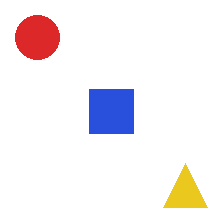

In [2]:
# Задание 1. Геометрический рендерер: цветные фигуры без перекрытий с фиксированными координатами
import hashlib
from PIL import Image, ImageDraw

IMG_SIZE = 224                    # сразу под вход ResNet18 (задание 8)
GRID = 3                          # сетка 3×3 → 9 фиксированных позиций (слотов)
CELL = IMG_SIZE // GRID           # 74 px
SHAPE_SIZE = 44                   # диаметр/сторона фигуры < CELL → между фигурами всегда есть зазор
BACKGROUND = (255, 255, 255)
PALETTE = {
    'red':    (220, 40, 40),
    'green':  (40, 160, 60),
    'blue':   (40, 80, 220),
    'yellow': (235, 200, 30),
    'purple': (140, 60, 180),
    'orange': (240, 130, 20),
}
SHAPES = ('circle', 'square', 'triangle')
# Фиксированные координаты: центры ячеек сетки, слоты 0..8 нумеруются построчно
SLOTS = [(CELL*c + CELL//2, CELL*r + CELL//2) for r in range(GRID) for c in range(GRID)]

def shape_bbox(slot):
    x, y = SLOTS[slot]; h = SHAPE_SIZE // 2
    return (x - h, y - h, x + h, y + h)

def boxes_overlap(a, b):
    return not (a[2] < b[0] or b[2] < a[0] or a[3] < b[1] or b[3] < a[1])

def render(spec, path=None):
    """spec = {'objects': [{'shape': 'circle', 'color': 'red', 'slot': 4}, ...]} → PIL.Image (и PNG, если задан path)."""
    objects = spec['objects']
    slots = [o['slot'] for o in objects]
    if len(set(slots)) != len(slots):
        raise ValueError(f'Два объекта в одном слоте: {slots}')
    boxes = [shape_bbox(s) for s in slots]
    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)):
            if boxes_overlap(boxes[i], boxes[j]):
                raise ValueError(f'Перекрытие фигур в слотах {slots[i]} и {slots[j]}')
    image = Image.new('RGB', (IMG_SIZE, IMG_SIZE), BACKGROUND)
    draw = ImageDraw.Draw(image)
    for obj, (x0, y0, x1, y1) in zip(objects, boxes):
        fill = PALETTE[obj['color']]
        if obj['shape'] == 'circle':
            draw.ellipse((x0, y0, x1, y1), fill=fill)
        elif obj['shape'] == 'square':
            draw.rectangle((x0, y0, x1, y1), fill=fill)
        elif obj['shape'] == 'triangle':
            draw.polygon([((x0 + x1) // 2, y0), (x1, y1), (x0, y1)], fill=fill)
        else:
            raise ValueError(f"Неизвестная фигура: {obj['shape']}")
    if path is not None:
        image.save(path, format='PNG')  # PNG без потерь → побайтово воспроизводимый файл
    return image

# Проверка инвариантов на фиксированной сцене
example_spec = {'objects': [{'shape': 'circle',   'color': 'red',    'slot': 0},
                            {'shape': 'square',   'color': 'blue',   'slot': 4},
                            {'shape': 'triangle', 'color': 'yellow', 'slot': 8}]}
example_path = ARTIFACTS/'render_example.png'
img = render(example_spec, example_path)
assert render(example_spec).tobytes() == img.tobytes(), 'render недетерминирован'
pixels = np.asarray(img)
mask = np.zeros(pixels.shape[:2], bool)
for o in example_spec['objects']:
    x0, y0, x1, y1 = shape_bbox(o['slot']); mask[y0:y1 + 1, x0:x1 + 1] = True
    assert (pixels[y0:y1 + 1, x0:x1 + 1] == PALETTE[o['color']]).all(axis=-1).any(), f'фигура {o} не нарисована'
assert (pixels[~mask] == BACKGROUND).all(), 'пиксели фигур вышли за свои bbox'
try:
    render({'objects': [{'shape': 'circle', 'color': 'red', 'slot': 1}, {'shape': 'square', 'color': 'blue', 'slot': 1}]})
    raise AssertionError('перекрытие не обнаружено')
except ValueError:
    pass

save_json('renderer_config.json', {
    'img_size': IMG_SIZE, 'grid': GRID, 'cell': CELL, 'shape_size': SHAPE_SIZE,
    'background': BACKGROUND, 'palette': PALETTE, 'shapes': SHAPES,
    'slots': {i: xy for i, xy in enumerate(SLOTS)},
    'example_spec': example_spec, 'example_png_sha256': hashlib.sha256(example_path.read_bytes()).hexdigest(),
})
print('Палитра:', PALETTE)
print('Слоты (центры):', SLOTS)
display(img)

### 2. Пространство визуальных сцен

*Вес: 1 балл.*

**Постановка.** Этап «пространство визуальных сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сгенерируйте воспроизводимые сочетания формы, цвета и числа объектов.
2. Сохраните и предъявите воспроизводимые спецификации фигур и количества.

**Результат.** воспроизводимые спецификации фигур и количества.

**Критерий принятия.** Задание считается принятым, если воспроизводимые спецификации фигур и количества получены из фактических входов этого этапа и доступны для проверки.

**Пространство визуальных сцен**

- **Что делали**: перебрали все сочетания «форма × цвет × количество» (3 × 6 × 3 = 54) и для каждого сгенерировали 4 разные раскладки по слотам. У каждой сцены свой seed = 42·100000 + номер.
- **Зачем**: получить сбалансированный и воспроизводимый набор описаний, по которым позже рисуются картинки. Разные раскладки не дают модели запомнить положение вместо количества.
- **Результат**: 216 спецификаций (описаний сцен. В следующем задании мы их рендерим) в `scene_specs.jsonl`: по 72 на каждое количество (1/2/3) и на каждую форму. Повторная генерация даёт тот же `specs_sha256` = `68bd72b8…`, раскладка каждой сцены восстанавливается по её seed.

In [3]:
# Задание 2. Пространство визуальных сцен: воспроизводимые сочетания формы, цвета и числа объектов
import itertools

COUNTS = (1, 2, 3)                          # 2 и 3 совпадают с классами реального PixMo-Count, 1 — только синтетика
LAYOUTS_PER_COMBO = 1 if FAST_DEV_RUN else 4  # сколько разных раскладок по слотам на одно сочетание
SHAPE_PLURAL = {'circle': 'circles', 'square': 'squares', 'triangle': 'triangles'}

def scene_seed(index):
    return SEED * 100_000 + index           # у каждой сцены свой seed → любую можно пересоздать отдельно

def make_scene_specs():
    """Полный перебор shape × color × count, для каждого сочетания — LAYOUTS_PER_COMBO разных раскладок."""
    specs = []
    for shape, color, count in itertools.product(SHAPES, PALETTE, COUNTS):
        used_layouts, attempt = set(), 0
        while len(used_layouts) < LAYOUTS_PER_COMBO:
            index = len(specs)
            seed = scene_seed(index) + attempt * 7_919  # сдвиг seed только при повторе раскладки
            slots = tuple(sorted(random.Random(seed).sample(range(len(SLOTS)), count)))
            attempt += 1
            if slots in used_layouts:       # одинаковая раскладка = точный дубликат картинки, пропускаем
                continue
            used_layouts.add(slots)
            specs.append({
                'id': f'syn-{index:05d}', 'seed': seed,
                'shape': shape, 'color': color, 'count': count,
                'objects': [{'shape': shape, 'color': color, 'slot': s} for s in slots],
                'question': f'How many {color} {SHAPE_PLURAL[shape]} are visible? Answer with one integer.',
                'answer': str(count),
            })
            attempt = 0
    return specs

scene_specs = make_scene_specs()

# Воспроизводимость: повторная генерация даёт побайтово те же спецификации,
# а раскладку каждой сцены можно восстановить только по её seed
specs_blob = json.dumps(scene_specs, sort_keys=True).encode()
assert json.dumps(make_scene_specs(), sort_keys=True).encode() == specs_blob, 'генерация спецификаций недетерминирована'
for s in scene_specs:
    assert sorted(random.Random(s['seed']).sample(range(len(SLOTS)), s['count'])) == [o['slot'] for o in s['objects']]
# Инварианты: число объектов = ответ, слоты различны, все сочетания покрыты поровну, рендер проходит без ошибок
for s in scene_specs:
    assert len(s['objects']) == s['count'] == int(s['answer'])
    assert len({o['slot'] for o in s['objects']}) == s['count']
    render(s)
combo_counts = {}
for s in scene_specs:
    combo_counts[(s['shape'], s['color'], s['count'])] = combo_counts.get((s['shape'], s['color'], s['count']), 0) + 1
assert len(combo_counts) == len(SHAPES) * len(PALETTE) * len(COUNTS)
assert set(combo_counts.values()) == {LAYOUTS_PER_COMBO}

specs_path = ARTIFACTS/'scene_specs.jsonl'
specs_path.write_text(''.join(json.dumps(s, ensure_ascii=False) + '\n' for s in scene_specs), encoding='utf-8')
summary = {
    'n_scenes': len(scene_specs), 'shapes': SHAPES, 'colors': list(PALETTE), 'counts': COUNTS,
    'layouts_per_combo': LAYOUTS_PER_COMBO, 'seed': SEED, 'fast_dev_run': FAST_DEV_RUN,
    'by_count': {c: sum(s['count'] == c for s in scene_specs) for c in COUNTS},
    'by_shape': {sh: sum(s['shape'] == sh for s in scene_specs) for sh in SHAPES},
    'specs_sha256': hashlib.sha256(specs_blob).hexdigest(),
}
save_json('scene_specs_summary.json', summary)
print(json.dumps(summary, ensure_ascii=False, indent=2))
for s in scene_specs[:3]:
    print(s)

{
  "n_scenes": 216,
  "shapes": [
    "circle",
    "square",
    "triangle"
  ],
  "colors": [
    "red",
    "green",
    "blue",
    "yellow",
    "purple",
    "orange"
  ],
  "counts": [
    1,
    2,
    3
  ],
  "layouts_per_combo": 4,
  "seed": 42,
  "fast_dev_run": false,
  "by_count": {
    "1": 72,
    "2": 72,
    "3": 72
  },
  "by_shape": {
    "circle": 72,
    "square": 72,
    "triangle": 72
  },
  "specs_sha256": "68bd72b8a36f2175d9217bbf911d1f9d5dbb100712fb8d494b21baa4ce999406"
}
{'id': 'syn-00000', 'seed': 4200000, 'shape': 'circle', 'color': 'red', 'count': 1, 'objects': [{'shape': 'circle', 'color': 'red', 'slot': 4}], 'question': 'How many red circles are visible? Answer with one integer.', 'answer': '1'}
{'id': 'syn-00001', 'seed': 4200001, 'shape': 'circle', 'color': 'red', 'count': 1, 'objects': [{'shape': 'circle', 'color': 'red', 'slot': 3}], 'question': 'How many red circles are visible? Answer with one integer.', 'answer': '1'}
{'id': 'syn-00002', 'seed':

### 3. Изображения и вопросы

*Вес: 1 балл.*

**Постановка.** Этап «изображения и вопросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения, вопрос и ответ для каждой сцены.
2. Сохраните и предъявите файлы изображений и связанные с ними ответы.

**Результат.** файлы изображений и связанные с ними ответы.

**Критерий принятия.** Задание считается принятым, если файлы изображений и связанные с ними ответы получены из фактических входов этого этапа и доступны для проверки.

**Изображения и вопросы**

- **Что делали**: отрендерили все 216 сцен в PNG (`data/lab12/synthetic/`) и связали каждую картинку с вопросом «How many {color} {shape}s are visible? Answer with one integer.» и ответом.
- **Зачем**: получить пары «картинка — вопрос — ответ» для проверки VLM и для обучения.
- **Результат**: 216 PNG и `synthetic_qa.jsonl`, превью `synthetic_preview.png`. Ответ всех 216 сцен подтверждён подсчётом по пикселям, все sha256 уникальны, все файлы 224×224 RGB.

Сохранено 216 изображений в C:\Users\bogom\OneDrive\Документы\PSY\6 курс\МО\data\lab12\synthetic
Вопросы и ответы: artifacts\lab12\synthetic_qa.jsonl
{
  "id": "syn-00000",
  "image": "C:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data\\lab12\\synthetic\\syn-00000.png",
  "image_sha256": "60d6e9cfe2599148b231198a7fd97b241e3ed121d684f300b22152ce839c4bf0",
  "question": "How many red circles are visible? Answer with one integer.",
  "answer": "1",
  "shape": "circle",
  "color": "red",
  "count": 1
}


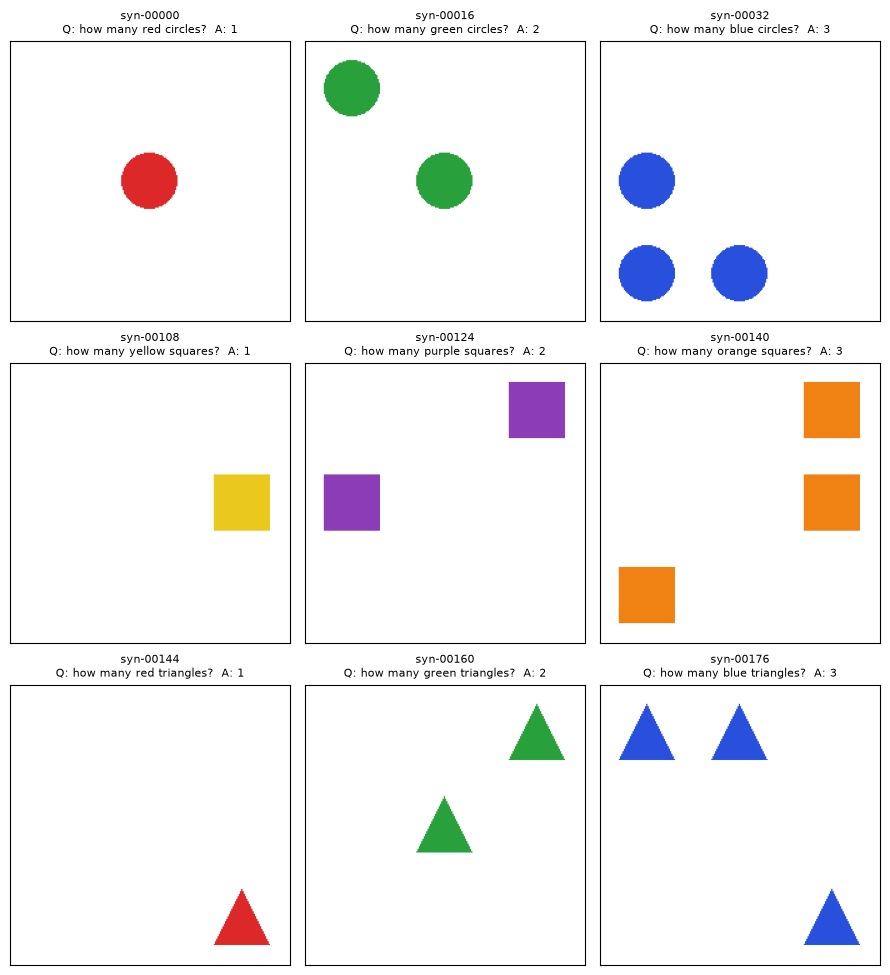

In [4]:
# Задание 3. Изображения и вопросы: PNG для каждой сцены + связанные вопрос и ответ
import matplotlib.pyplot as plt

def count_from_pixels(image, color):
    """Независимая проверка ответа по самой картинке: в скольких слотах есть пиксели цвета color."""
    pixels = np.asarray(image)
    hits = 0
    for slot in range(len(SLOTS)):
        x0, y0, x1, y1 = shape_bbox(slot)
        hits += bool((pixels[y0:y1 + 1, x0:x1 + 1] == PALETTE[color]).all(axis=-1).any())
    return hits

synthetic_qa = []
for spec in scene_specs:
    path = SYN_DIR/f"{spec['id']}.png"
    image = render(spec, path)
    assert count_from_pixels(image, spec['color']) == int(spec['answer']), f"{spec['id']}: ответ не совпадает с картинкой"
    synthetic_qa.append({
        'id': spec['id'], 'image': str(path.resolve()),
        'image_sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
        'question': spec['question'], 'answer': spec['answer'],
        'shape': spec['shape'], 'color': spec['color'], 'count': spec['count'],
    })

# Проверки: все файлы на месте, читаются, хэши уникальны (точных дубликатов картинок нет)
for r in synthetic_qa:
    with Image.open(r['image']) as im:
        assert im.size == (IMG_SIZE, IMG_SIZE) and im.mode == 'RGB'
assert len({r['image_sha256'] for r in synthetic_qa}) == len(synthetic_qa), 'есть побайтово одинаковые картинки'

qa_path = ARTIFACTS/'synthetic_qa.jsonl'
qa_path.write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in synthetic_qa), encoding='utf-8')
print(f'Сохранено {len(synthetic_qa)} изображений в {SYN_DIR.resolve()}')
print(f'Вопросы и ответы: {qa_path}')
print(json.dumps(synthetic_qa[0], ensure_ascii=False, indent=2))

# Превью: по одной сцене на каждое сочетание форма × количество, цвета чередуются
preview = [next(r for r in synthetic_qa if r['shape'] == sh and r['count'] == c and r['color'] == list(PALETTE)[i % len(PALETTE)])
           for i, (sh, c) in enumerate(itertools.product(SHAPES, COUNTS))]
fig, axes = plt.subplots(len(SHAPES), len(COUNTS), figsize=(3 * len(COUNTS), 3.3 * len(SHAPES)))
for ax, r in zip(axes.flat, preview):
    ax.imshow(Image.open(r['image'])); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{r['id']}\nQ: how many {r['color']} {r['shape']}s?  A: {r['answer']}", fontsize=8)
fig.tight_layout(); fig.savefig(ARTIFACTS/'synthetic_preview.png', dpi=120)
plt.show()

### 4. Происхождение синтетических данных

*Вес: 1 балл.*

**Постановка.** Этап «происхождение синтетических данных» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Зафиксируйте seed, спецификацию, пути и provenance в манифесте.
2. Сохраните и предъявите artifacts/synthetic_manifest.jsonl.

**Результат.** artifacts/synthetic_manifest.jsonl.

**Критерий принятия.** Задание считается принятым, если artifacts/synthetic_manifest.jsonl получены из фактических входов этого этапа и доступны для проверки.

**Происхождение синтетических данных**

- **Что делали**: собрали манифест (как она получилась, откуда, чтобы её можно было в любой момент воспроизвести): для каждой сцены id, seed, спецификация, пути, sha256 картинки, вопрос, ответ и блок provenance (генератор, sha256 конфигурации и описаний сцен, версии Python 3.12.1 / Pillow 12.3.0 / NumPy 2.5.3, `origin: synthetic`).
- **Зачем**: любую синтетическую картинку можно восстановить и проверить по одной записи; синтетика никогда не помечается как реальная.
- **Результат**: `synthetic_manifest.jsonl`, 216 записей. Для всех 216 seed воспроизводит раскладку, хеш файла совпадает, повторный рендер совпадает с сохранённой картинкой пиксель в пиксель.

In [5]:
# Задание 4. Происхождение синтетических данных: seed, спецификация, пути и provenance в манифесте
import platform, sys
from datetime import datetime, timezone
import PIL

renderer_config_path = ARTIFACTS/'renderer_config.json'
PROVENANCE = {
    'origin': 'synthetic',                       # синтетика никогда не помечается как real
    'generator': 'procedural PIL renderer (render, задание 1)',
    'renderer_config': str(renderer_config_path.resolve()),
    'renderer_config_sha256': hashlib.sha256(renderer_config_path.read_bytes()).hexdigest(),
    'scene_specs_sha256': summary['specs_sha256'],
    'global_seed': SEED,
    'seed_rule': 'seed = SEED*100000 + index (+ 7919*attempt при повторе раскладки); slots = sorted(Random(seed).sample(range(9), count))',
    'libraries': {'python': platform.python_version(), 'pillow': PIL.__version__, 'numpy': np.__version__},
    'created_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'fast_dev_run': FAST_DEV_RUN,
}

qa_by_id = {r['id']: r for r in synthetic_qa}
synthetic_manifest = []
for spec in scene_specs:
    qa = qa_by_id[spec['id']]
    synthetic_manifest.append({
        'id': spec['id'], 'split': 'synthetic', 'origin': 'synthetic',
        'seed': spec['seed'],
        'spec': {'shape': spec['shape'], 'color': spec['color'], 'count': spec['count'], 'objects': spec['objects']},
        'image': qa['image'], 'image_relpath': Path(os.path.relpath(qa['image'])).as_posix(),
        'image_sha256': qa['image_sha256'],
        'question': spec['question'], 'answer': spec['answer'],
        'provenance': PROVENANCE,
    })

# Проверка манифеста: каждую запись можно воспроизвести только из неё самой
for m in synthetic_manifest:
    slots = sorted(random.Random(m['seed']).sample(range(len(SLOTS)), m['spec']['count']))
    assert slots == [o['slot'] for o in m['spec']['objects']], f"{m['id']}: seed не воспроизводит раскладку"
    assert Path(m['image']).is_file(), f"{m['id']}: нет файла"
    assert hashlib.sha256(Path(m['image']).read_bytes()).hexdigest() == m['image_sha256'], f"{m['id']}: файл изменён"
    assert np.array_equal(np.asarray(render(m['spec'])), np.asarray(Image.open(m['image']).convert('RGB'))), f"{m['id']}: рендер не совпадает"
    assert m['answer'] == str(m['spec']['count']) and m['origin'] == 'synthetic'
assert len({m['id'] for m in synthetic_manifest}) == len(synthetic_manifest)

manifest_path = ARTIFACTS/'synthetic_manifest.jsonl'
manifest_path.write_text(''.join(json.dumps(m, ensure_ascii=False) + '\n' for m in synthetic_manifest), encoding='utf-8')
print(f'{manifest_path}: {len(synthetic_manifest)} записей, sha256 = {hashlib.sha256(manifest_path.read_bytes()).hexdigest()}')
print(json.dumps(synthetic_manifest[0], ensure_ascii=False, indent=2))

artifacts\lab12\synthetic_manifest.jsonl: 216 записей, sha256 = 4fcbbbb2c27a9f8d554ef73894e94ad67a44c5c380b50e8a0b87d3cf9a65dbe4
{
  "id": "syn-00000",
  "split": "synthetic",
  "origin": "synthetic",
  "seed": 4200000,
  "spec": {
    "shape": "circle",
    "color": "red",
    "count": 1,
    "objects": [
      {
        "shape": "circle",
        "color": "red",
        "slot": 4
      }
    ]
  },
  "image": "C:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data\\lab12\\synthetic\\syn-00000.png",
  "image_relpath": "data/lab12/synthetic/syn-00000.png",
  "image_sha256": "60d6e9cfe2599148b231198a7fd97b241e3ed121d684f300b22152ce839c4bf0",
  "question": "How many red circles are visible? Answer with one integer.",
  "answer": "1",
  "provenance": {
    "origin": "synthetic",
    "generator": "procedural PIL renderer (render, задание 1)",
    "renderer_config": "C:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\artifacts\\lab12\\renderer_config.json",
    "renderer_config_s

### 5. Ответы VLM и визуальная дедупликация

*Вес: 1 балл.*

**Постановка.** Этап «ответы vlm и визуальная дедупликация» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Спросите реальную VLM о числе фигур и найдите дубли по хешу пикселей.
2. Сохраните и предъявите artifacts/verification.jsonl с реальными ответами VLM.

**Результат.** artifacts/verification.jsonl с реальными ответами VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/verification.jsonl с реальными ответами VLM получены из фактических входов этого этапа и доступны для проверки.

**Ответы VLM и визуальная дедупликация**

- **Что делали**: посчитали sha256 пикселей каждой картинки для поиска дублей. Задали Qwen2.5-VL-3B-Instruct (4-bit nf4, greedy) вопрос к каждой из 216 картинок: 14 батчей по 16, около 19 с на RTX 3060.
- **Зачем**: получить независимую проверку синтетики реальной моделью и найти точные дубли.
- **Результат**: `verification.jsonl` и `verification_summary.json`. Квен ответил верно на 216 из 216 (100%), ответов без числа 0, дублей по хешу пикселей 0.

In [6]:
# Задание 5. Ответы VLM и визуальная дедупликация по хешу пикселей
import re

VERIFICATION_PATH = ARTIFACTS/'verification.jsonl'
BATCH_SIZE = int(os.getenv('CV_VLM_BATCH', 16))
GEN_CONFIG = {'max_new_tokens': 96, 'do_sample': False}   # как в infer_image из VLM_LOADER

# 1) Дедупликация: хеш декодированных пикселей (не байтов файла — PNG-метаданные/сжатие на него не влияют)
def pixel_sha256(path):
    pixels = np.asarray(Image.open(path).convert('RGB'))
    return hashlib.sha256(str(pixels.shape).encode() + pixels.tobytes()).hexdigest()

first_by_hash, dedup = {}, {}
for m in synthetic_manifest:
    h = pixel_sha256(m['image'])
    dedup[m['id']] = {'pixel_sha256': h, 'duplicate_of': first_by_hash.setdefault(h, m['id'])}
n_duplicates = sum(d['duplicate_of'] != i for i, d in dedup.items())
print(f'Уникальных по пикселям: {len(first_by_hash)} из {len(synthetic_manifest)}, дублей: {n_duplicates}')

# 2) Реальная VLM: Qwen2.5-VL из VLM_LOADER (GPU обязателен, подменять ответы нельзя)
exec(VLM_LOADER)  # определяет torch, Image, MODEL_ID, processor, model, infer_image

def infer_batch(paths, prompts):
    """Батчевый аналог infer_image: тот же chat template и greedy-декодирование, паддинг слева."""
    images = [Image.open(p).convert('RGB') for p in paths]
    texts = [processor.apply_chat_template(
                 [{'role': 'user', 'content': [{'type': 'image', 'image': img}, {'type': 'text', 'text': pr}]}],
                 tokenize=False, add_generation_prompt=True) for img, pr in zip(images, prompts)]
    processor.tokenizer.padding_side = 'left'
    inputs = processor(text=texts, images=images, padding=True, return_tensors='pt').to(model.device)
    with torch.no_grad():
        generated = model.generate(**inputs, **GEN_CONFIG, pad_token_id=processor.tokenizer.pad_token_id)
    return [s.strip() for s in processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)]

NUMBER_WORDS = {w: i for i, w in enumerate('zero one two three four five six seven eight nine ten'.split())}
def parse_count(text):
    """Первое целое в ответе (цифрами или словом); None, если числа нет."""
    match = re.search(r'\b(\d+|' + '|'.join(NUMBER_WORDS) + r')\b', text.lower())
    if match is None:
        return None
    token = match.group(1)
    return int(token) if token.isdigit() else NUMBER_WORDS[token]

# Возобновляемость: уже полученные ответы этой же модели не запрашиваются повторно
done = {}
if VERIFICATION_PATH.exists():
    for line in VERIFICATION_PATH.read_text(encoding='utf-8').splitlines():
        r = json.loads(line)
        if r['model_id'] == MODEL_ID:
            done[r['id']] = r

todo = [m for m in synthetic_manifest if m['id'] not in done]
print(f'VLM {MODEL_ID}: уже есть {len(done)}, осталось {len(todo)}')
with VERIFICATION_PATH.open('a', encoding='utf-8') as f:
    for start in range(0, len(todo), BATCH_SIZE):
        batch = todo[start:start + BATCH_SIZE]
        t0 = time.perf_counter()
        answers = infer_batch([m['image'] for m in batch], [m['question'] for m in batch])
        seconds = time.perf_counter() - t0
        for m, raw in zip(batch, answers):
            parsed = parse_count(raw)
            r = {'id': m['id'], 'image': m['image'], 'origin': m['origin'],
                 'question': m['question'], 'expected': int(m['answer']),
                 'vlm_raw': raw, 'vlm_count': parsed, 'parse_ok': parsed is not None,
                 'vlm_correct': parsed == int(m['answer']),
                 **dedup[m['id']], 'is_duplicate': dedup[m['id']]['duplicate_of'] != m['id'],
                 'model_id': MODEL_ID, 'quantization': 'bnb-4bit nf4', 'generation': GEN_CONFIG,
                 'batch_seconds': round(seconds, 3), 'created_at': datetime.now(timezone.utc).isoformat(timespec='seconds')}
            done[m['id']] = r
            f.write(json.dumps(r, ensure_ascii=False) + '\n')
        f.flush()
        print(f'  {start + len(batch)}/{len(todo)}  ({seconds:.1f} c на батч)')

# Перезаписываем файл в порядке манифеста, с актуальной дедупликацией
verification = [{**done[m['id']], **dedup[m['id']], 'is_duplicate': dedup[m['id']]['duplicate_of'] != m['id']}
                for m in synthetic_manifest]
VERIFICATION_PATH.write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in verification), encoding='utf-8')
assert len(verification) == len(synthetic_manifest) and all(r['vlm_raw'] is not None for r in verification)

verification_summary = {
    'model_id': MODEL_ID, 'n': len(verification),
    'pixel_duplicates': n_duplicates,
    'parse_failures': sum(not r['parse_ok'] for r in verification),
    'vlm_accuracy': round(np.mean([r['vlm_correct'] for r in verification]), 4),
    'vlm_accuracy_by_count': {c: round(np.mean([r['vlm_correct'] for r in verification if r['expected'] == c]), 4) for c in COUNTS},
    'vlm_accuracy_by_shape': {sh: round(np.mean([r['vlm_correct'] for r, m in zip(verification, synthetic_manifest) if m['spec']['shape'] == sh]), 4) for sh in SHAPES},
}
save_json('verification_summary.json', verification_summary)
print(json.dumps(verification_summary, ensure_ascii=False, indent=2))
print('Примеры ошибок VLM:')
for r in [r for r in verification if not r['vlm_correct']][:5]:
    print(f"  {r['id']}: ожидалось {r['expected']}, VLM: {r['vlm_raw']!r}")

Уникальных по пикселям: 216 из 216, дублей: 0


W1023 23:09:44.033000 15088 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

VLM Qwen/Qwen2.5-VL-3B-Instruct: уже есть 216, осталось 0
{
  "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
  "n": 216,
  "pixel_duplicates": 0,
  "parse_failures": 0,
  "vlm_accuracy": 1.0,
  "vlm_accuracy_by_count": {
    "1": 1.0,
    "2": 1.0,
    "3": 1.0
  },
  "vlm_accuracy_by_shape": {
    "circle": 1.0,
    "square": 1.0,
    "triangle": 1.0
  }
}
Примеры ошибок VLM:


**Шаблон вопроса к VLM.** Вопрос собирается в задании 2 из спецификации сцены:

```
How many {color} {shape}s are visible? Answer with one integer.
```

`{color}` — ключ `PALETTE`, `{shape}s` — множественное число из `SHAPE_PLURAL` (например, *How many red circles are visible? Answer with one integer.*). Квен получает картинку и этот текст одним user-сообщением, без системного промпта и примеров. Формулировка совпадает с вопросом к реальным фото PixMo-Count (`How many {label} are visible? Answer with one integer.`), а фраза «Answer with one integer» нужна, чтобы `parse_count` надёжно извлекал число.

### 6. Отбор согласованных пар

*Вес: 1 балл.*

**Постановка.** Этап «отбор согласованных пар» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите только изображения с согласованным ответом и без дублей.
2. Сохраните и предъявите artifacts/accepted.jsonl после проверки ответов.

**Результат.** artifacts/accepted.jsonl после проверки ответов.

**Критерий принятия.** Задание считается принятым, если artifacts/accepted.jsonl после проверки ответов получены из фактических входов этого этапа и доступны для проверки.

**Отбор согласованных пар**

- **Что делали**: из манифеста и ответов VLM оставили сцены, где ответ разобран, совпал с правильным, картинка не дубль и файл не изменён. Отклонённые записаны отдельно с причиной.
- **Зачем**: обучать только на парах, правильность которых подтверждена и рендерером, и VLM.
- **Результат**: `accepted.jsonl`: принято 216 из 216, `rejected.jsonl` пуст, баланс сохранён (72 / 72 / 72). Фильтр ничего не отсеял: простые сцены VLM считает без ошибок.

In [7]:
# Задание 6. Отбор согласованных пар: только ответ VLM == ответ рендерера и без дублей
def read_jsonl(path):
    return [json.loads(s) for s in Path(path).read_text(encoding='utf-8').splitlines() if s.strip()]

# Читаем сохранённые артефакты заданий 4–5: отбор не требует повторной загрузки VLM
manifest_rows = read_jsonl(ARTIFACTS/'synthetic_manifest.jsonl')
verification_rows = {r['id']: r for r in read_jsonl(ARTIFACTS/'verification.jsonl')}
assert set(verification_rows) == {m['id'] for m in manifest_rows}, 'verification.jsonl не покрывает манифест'

def reject_reason(m, v):
    if not v['parse_ok']:
        return 'vlm_unparsed'
    if not v['vlm_correct']:
        return 'vlm_disagrees'
    if v['is_duplicate']:
        return 'pixel_duplicate'
    if hashlib.sha256(Path(m['image']).read_bytes()).hexdigest() != m['image_sha256']:
        return 'image_changed'
    return None

accepted, rejected = [], []
for m in manifest_rows:
    v = verification_rows[m['id']]
    reason = reject_reason(m, v)
    if reason is None:
        accepted.append({**m, 'vlm_model_id': v['model_id'], 'vlm_raw': v['vlm_raw'],
                         'vlm_count': v['vlm_count'], 'pixel_sha256': v['pixel_sha256']})
    else:
        rejected.append({'id': m['id'], 'reason': reason, 'expected': v['expected'], 'vlm_raw': v['vlm_raw']})

# Проверки отобранного набора
for a in accepted:
    assert a['origin'] == 'synthetic' and str(a['vlm_count']) == a['answer']
assert len({a['pixel_sha256'] for a in accepted}) == len(accepted), 'в accepted остались дубли'
assert len(accepted) + len(rejected) == len(manifest_rows)

accepted_path = ARTIFACTS/'accepted.jsonl'
accepted_path.write_text(''.join(json.dumps(a, ensure_ascii=False) + '\n' for a in accepted), encoding='utf-8')
(ARTIFACTS/'rejected.jsonl').write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in rejected), encoding='utf-8')

counts_all = {c: sum(m['spec']['count'] == c for m in manifest_rows) for c in COUNTS}
acceptance_summary = {
    'n_total': len(manifest_rows), 'n_accepted': len(accepted), 'n_rejected': len(rejected),
    'acceptance_rate': round(len(accepted) / len(manifest_rows), 4),
    'rejected_by_reason': {r: sum(x['reason'] == r for x in rejected) for r in sorted({x['reason'] for x in rejected})},
    'accepted_by_count': {c: sum(a['spec']['count'] == c for a in accepted) for c in COUNTS},
    'acceptance_rate_by_count': {c: round(sum(a['spec']['count'] == c for a in accepted) / counts_all[c], 4) for c in COUNTS},
    'accepted_by_shape': {sh: sum(a['spec']['shape'] == sh for a in accepted) for sh in SHAPES},
    'vlm_model_id': next(iter(verification_rows.values()))['model_id'],
    'accepted_sha256': hashlib.sha256(accepted_path.read_bytes()).hexdigest(),
}
save_json('acceptance_summary.json', acceptance_summary)
print(json.dumps(acceptance_summary, ensure_ascii=False, indent=2))
if any(n == 0 for n in acceptance_summary['accepted_by_count'].values()):
    print('ВНИМАНИЕ: после фильтрации пропал целый класс количества — смеси в задании 9 будут несбалансированы')

{
  "n_total": 216,
  "n_accepted": 216,
  "n_rejected": 0,
  "acceptance_rate": 1.0,
  "rejected_by_reason": {},
  "accepted_by_count": {
    "1": 72,
    "2": 72,
    "3": 72
  },
  "acceptance_rate_by_count": {
    "1": 1.0,
    "2": 1.0,
    "3": 1.0
  },
  "accepted_by_shape": {
    "circle": 72,
    "square": 72,
    "triangle": 72
  },
  "vlm_model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
  "accepted_sha256": "5566505b8a3c6fd3c2eb83a3960998070f5d55279fbbebf98e2c8a83eaa500b3"
}


### 7. Независимый набор реальных изображений

*Вес: 1 балл.*

**Постановка.** Этап «независимый набор реальных изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Скачайте PixMo-Count validation для обучения и официальный test для отложенной оценки; проверьте метки и отсутствие общих ID/изображений.
2. Сохраните и предъявите проверенный real train/test manifest с источником, split и контрольными суммами.

**Результат.** проверенный real train/test manifest с источником, split и контрольными суммами.

**Критерий принятия.** Задание считается принятым, если проверенный real train/test manifest получены из фактических входов этого этапа и доступны для проверки.

**Независимый набор реальных изображений**

- **Что делали**: через `open_real_scenes.py` скачали фото PixMo-Count с 2 и 3 объектами: real train из human-verified validation, real test из официального test. Проверили split, метки, файлы и пересечения.
- **Зачем**: получить реальный набор, на котором честно измеряется перенос, и отделить его от обучения.
- **Результат**: `real_manifest.jsonl`: train 24 фото (12 + 12), test 12 (6 + 6). Пересечений train/test 0 по хешу PixMo, хешу файла, хешу пикселей и URL. У 32 из 36 файлов хеш не совпал с PixMo, потому что Flickr отдаёт заново закодированный JPEG; это записано в манифест.

In [8]:
# Задание 7. Независимый набор реальных изображений: PixMo-Count validation → train, official test → test
from open_real_scenes import load_real_scenes

REAL_TRAIN_SIZE, REAL_TEST_SIZE = (8, 4) if FAST_DEV_RUN else (24, 12)
real_manifest_path = DATA_DIR/'real_manifest.jsonl'

def cached_real_manifest():
    """Повторно используем уже скачанный набор, если он полон и файлы не изменились."""
    if not real_manifest_path.exists():
        return None
    rows = read_jsonl(real_manifest_path)
    sizes = (sum(r['split'] == 'train' for r in rows), sum(r['split'] == 'test' for r in rows))
    if sizes != (REAL_TRAIN_SIZE, REAL_TEST_SIZE):
        return None
    if not all(Path(r['image']).is_file() and hashlib.sha256(Path(r['image']).read_bytes()).hexdigest() == r['downloaded_sha256'] for r in rows):
        return None
    return rows

real_rows = cached_real_manifest()
if real_rows is None:
    real_rows = load_real_scenes(DATA_DIR, train_size=REAL_TRAIN_SIZE, test_size=REAL_TEST_SIZE)
    print('Скачано с HF datasets-server:', len(real_rows))
else:
    print('Использован сохранённый real_manifest.jsonl:', len(real_rows))

# Проверки: split ↔ официальный источник, метки, файлы, отсутствие общих ID/изображений
SPLIT_SOURCE = {'train': 'validation', 'test': 'test'}
for r in real_rows:
    assert SPLIT_SOURCE[r['split']] == r['source_split'], f"{r['id']}: split не соответствует источнику"
    assert r['answer'] in {'2', '3'} and r['label'].strip(), f"{r['id']}: некорректная метка"
    assert r['question'] == f"How many {r['label']} are visible? Answer with one integer."
    with Image.open(r['image']) as im:
        im.verify()
    assert hashlib.sha256(Path(r['image']).read_bytes()).hexdigest() == r['downloaded_sha256']
    r['pixel_sha256'] = pixel_sha256(r['image'])
    r['origin'] = 'real'

train_rows = [r for r in real_rows if r['split'] == 'train']
test_rows = [r for r in real_rows if r['split'] == 'test']
assert (len(train_rows), len(test_rows)) == (REAL_TRAIN_SIZE, REAL_TEST_SIZE)
assert len({r['id'] for r in real_rows}) == len(real_rows), 'повторяющиеся id'
overlap = {key: {r[key] for r in train_rows} & {r[key] for r in test_rows}
           for key in ('image_sha256', 'downloaded_sha256', 'pixel_sha256', 'image_url')}
assert not any(overlap.values()), f'train/test пересекаются: {overlap}'
syn_hashes = {m['pixel_sha256'] for m in accepted}
assert not syn_hashes & {r['pixel_sha256'] for r in real_rows}, 'синтетика попала в реальный набор'
for split_rows in (train_rows, test_rows):
    assert {r['answer'] for r in split_rows} == {'2', '3'}, 'в split нет одного из классов'

mismatched = [r['id'] for r in real_rows if not r['checksum_matches']]
if mismatched:
    # Flickr отдаёт заново закодированные файлы, поэтому побайтовое совпадение с хешем PixMo редкость;
    # метки при этом относятся к той же фотографии (тот же image_url), фиксируем расхождение в манифесте
    print(f'ВНИМАНИЕ: у {len(mismatched)}/{len(real_rows)} фото хеш файла ≠ image_sha256 PixMo, например: {mismatched[:5]}')

real_manifest_artifact = ARTIFACTS/'real_manifest.jsonl'
real_manifest_artifact.write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in real_rows), encoding='utf-8')
real_summary = {
    'source': 'https://huggingface.co/datasets/allenai/pixmo-count',
    'dataset_license': 'ODC-BY-1.0; image rights may differ',
    'split_source': SPLIT_SOURCE,
    'sizes': {'train': len(train_rows), 'test': len(test_rows)},
    'by_answer': {s: {a: sum(r['answer'] == a for r in rows) for a in ('2', '3')} for s, rows in (('train', train_rows), ('test', test_rows))},
    'checksum_mismatches': mismatched,
    'train_test_overlap': {k: len(v) for k, v in overlap.items()},
    'manifest_sha256': hashlib.sha256(real_manifest_artifact.read_bytes()).hexdigest(),
}
save_json('real_summary.json', real_summary)
print(json.dumps(real_summary, ensure_ascii=False, indent=2))
for r in test_rows[:3]:
    print(r['id'], r['label'], r['answer'], r['image_url'])

Использован сохранённый real_manifest.jsonl: 36
ВНИМАНИЕ: у 32/36 фото хеш файла ≠ image_sha256 PixMo, например: ['pixmo-count-train-6', 'pixmo-count-train-7', 'pixmo-count-train-11', 'pixmo-count-train-13', 'pixmo-count-train-21']
{
  "source": "https://huggingface.co/datasets/allenai/pixmo-count",
  "dataset_license": "ODC-BY-1.0; image rights may differ",
  "split_source": {
    "train": "validation",
    "test": "test"
  },
  "sizes": {
    "train": 24,
    "test": 12
  },
  "by_answer": {
    "train": {
      "2": 12,
      "3": 12
    },
    "test": {
      "2": 6,
      "3": 6
    }
  },
  "checksum_mismatches": [
    "pixmo-count-train-6",
    "pixmo-count-train-7",
    "pixmo-count-train-11",
    "pixmo-count-train-13",
    "pixmo-count-train-21",
    "pixmo-count-train-26",
    "pixmo-count-train-32",
    "pixmo-count-train-38",
    "pixmo-count-train-43",
    "pixmo-count-train-58",
    "pixmo-count-train-64",
    "pixmo-count-train-66",
    "pixmo-count-train-77",
    "pixm

### 8. Признаки реальных и синтетических сцен

*Вес: 1 балл.*

**Постановка.** Этап «признаки реальных и синтетических сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите одинаковые замороженные признаки ResNet18 для real train, synthetic и real test.
2. Сохраните и предъявите замороженные признаки ResNet18 для трёх наборов.

**Результат.** замороженные признаки ResNet18 для трёх наборов.

**Критерий принятия.** Задание считается принятым, если замороженные признаки ResNet18 для трёх наборов получены из фактических входов этого этапа и доступны для проверки.

**Признаки реальных и синтетических сцен**

- **Что делали**: прогнали все три набора через один замороженный ResNet18 (IMAGENET1K_V1, без `fc`) с одинаковым препроцессингом: 224×224 без center crop, нормализация ImageNet.
- **Зачем**: получить сравнимые 512-мерные векторы для обучения классификаторов на смесях.
- **Результат**: `features_resnet18.npz`: real train 24 × 512, synthetic 216 × 512, real test 12 × 512. Среднее косинусное сходство синтетика ↔ test 0.46 против 0.57 у real train ↔ test (разрыв доменов). Найдены 2 пары почти-дублей синтетики (cos > 0.99).

In [9]:
# Задание 8. Замороженные признаки ResNet18 для real train, synthetic и real test
import torch
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(SEED)

WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
backbone = resnet18(weights=WEIGHTS)
backbone.fc = torch.nn.Identity()          # выход — 512-мерный вектор после global average pooling
backbone = backbone.eval().to(DEVICE)
for p in backbone.parameters():
    p.requires_grad_(False)                 # признаки заморожены: backbone не обучается

# Один и тот же препроцессинг для всех трёх наборов. Без center crop: на реальных фото
# обрезка краёв могла бы убрать объекты и изменить правильный ответ на «сколько».
PREPROCESS = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BILINEAR, antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(mean=WEIGHTS.transforms().mean, std=WEIGHTS.transforms().std),
])

@torch.no_grad()
def extract_features(paths, batch_size=64):
    chunks = []
    for start in range(0, len(paths), batch_size):
        batch = torch.stack([PREPROCESS(Image.open(p).convert('RGB')) for p in paths[start:start + batch_size]])
        chunks.append(backbone(batch.to(DEVICE)).float().cpu().numpy())
    return np.concatenate(chunks)

FEATURE_SETS = {
    'real_train': [r for r in real_rows if r['split'] == 'train'],
    'synthetic':  accepted,
    'real_test':  [r for r in real_rows if r['split'] == 'test'],
}
features = {}
for name, rows in FEATURE_SETS.items():
    X = extract_features([r['image'] for r in rows])
    features[name] = {'X': X, 'y': np.array([int(r['answer']) for r in rows]), 'ids': np.array([r['id'] for r in rows])}
    assert X.shape == (len(rows), 512) and np.isfinite(X).all()
    print(f'{name:10s}: X {X.shape}, классы {dict(zip(*map(np.ndarray.tolist, np.unique(features[name]["y"], return_counts=True))))}')

# Воспроизводимость: повторное извлечение с тем же разбиением на батчи даёт те же признаки
# (при другом размере батча на GPU возможны расхождения ~1e-3 из-за выбора cuDNN-алгоритма)
for name, rows in FEATURE_SETS.items():
    again = extract_features([r['image'] for r in rows])
    assert np.allclose(again, features[name]['X'], atol=1e-5), f'{name}: признаки нестабильны'

features_path = ARTIFACTS/'features_resnet18.npz'
np.savez_compressed(features_path, **{f'{n}_{k}': v for n, d in features.items() for k, v in d.items()})

# Косинусные сходства: визуальные почти-дубли синтетики и разрыв доменов real ↔ synthetic
def l2n(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)
def mean_cos(A, B, same=False):
    S = l2n(A) @ l2n(B).T
    return float(S[~np.eye(len(A), dtype=bool)].mean() if same else S.mean())
S_syn = l2n(features['synthetic']['X']) @ l2n(features['synthetic']['X']).T
np.fill_diagonal(S_syn, -1)
NEAR_DUP_THRESHOLD = 0.99
near_dup_pairs = [(features['synthetic']['ids'][i], features['synthetic']['ids'][j], round(float(S_syn[i, j]), 4))
                  for i, j in zip(*np.where(np.triu(S_syn > NEAR_DUP_THRESHOLD, 1)))]
Xr, Xs, Xt = (features[n]['X'] for n in ('real_train', 'synthetic', 'real_test'))

features_meta = {
    'backbone': 'torchvision resnet18', 'weights': str(WEIGHTS), 'frozen': True, 'feature_dim': 512,
    'preprocess': 'Resize(224x224, bilinear, antialias) → ToTensor → Normalize(ImageNet mean/std); без crop',
    'device': DEVICE, 'torch': torch.__version__,
    'sizes': {n: int(len(d['y'])) for n, d in features.items()},
    'labels': {n: {int(c): int(k) for c, k in zip(*np.unique(d['y'], return_counts=True))} for n, d in features.items()},
    'mean_cosine': {
        'real_train↔real_train': round(mean_cos(Xr, Xr, same=True), 4),
        'synthetic↔synthetic': round(mean_cos(Xs, Xs, same=True), 4),
        'real_train↔real_test': round(mean_cos(Xr, Xt), 4),
        'synthetic↔real_test': round(mean_cos(Xs, Xt), 4),
    },
    'synthetic_near_duplicates': {'threshold': NEAR_DUP_THRESHOLD, 'n_pairs': len(near_dup_pairs), 'examples': near_dup_pairs[:10]},
    'features_sha256': hashlib.sha256(features_path.read_bytes()).hexdigest(),
}
save_json('features_meta.json', features_meta)
print(json.dumps({k: features_meta[k] for k in ('sizes', 'labels', 'mean_cosine', 'synthetic_near_duplicates')}, ensure_ascii=False, indent=2))

real_train: X (24, 512), классы {2: 12, 3: 12}
synthetic : X (216, 512), классы {1: 72, 2: 72, 3: 72}
real_test : X (12, 512), классы {2: 6, 3: 6}
{
  "sizes": {
    "real_train": 24,
    "synthetic": 216,
    "real_test": 12
  },
  "labels": {
    "real_train": {
      "2": 12,
      "3": 12
    },
    "synthetic": {
      "1": 72,
      "2": 72,
      "3": 72
    },
    "real_test": {
      "2": 6,
      "3": 6
    }
  },
  "mean_cosine": {
    "real_train↔real_train": 0.5794,
    "synthetic↔synthetic": 0.7241,
    "real_train↔real_test": 0.572,
    "synthetic↔real_test": 0.4619
  },
  "synthetic_near_duplicates": {
    "threshold": 0.99,
    "n_pairs": 2,
    "examples": [
      [
        "syn-00009",
        "syn-00010",
        0.9949
      ],
      [
        "syn-00088",
        "syn-00090",
        0.9917
      ]
    ]
  }
}


### 9. Обучение на смесях

*Вес: 1 балл.*

**Постановка.** Этап «обучение на смесях» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. При постоянном бюджете train обучите классификаторы с четырьмя долями синтетики.
2. Сохраните и предъявите результаты классификаторов при четырёх долях синтетики.

**Результат.** результаты классификаторов при четырёх долях синтетики.

**Критерий принятия.** Задание считается принятым, если результаты классификаторов при четырёх долях синтетики получены из фактических входов этого этапа и доступны для проверки.

**Обучение на смесях**

- **Что делали**: при постоянном бюджете 16 примеров обучили `StandardScaler → LogisticRegression` для α = 0 / 0.25 / 0.5 / 1 (real/syn = 16/0, 12/4, 8/8, 0/16), по 20 повторов с разными подвыборками; только классы 2 и 3, поровну.
- **Зачем**: сравнить смеси реальных и синтетических данных при одинаковом объёме обучения.
- **Результат**: 80 моделей в `mixture_models.joblib`, журнал `mixture_training.jsonl`. Все 80 сошлись, accuracy на train у всех 1.0, то есть 16 примеров запоминаются полностью.

In [10]:
# Задание 9. Обучение на смесях D_α = (1-α)·D_real + α·D_syn при постоянном бюджете train
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ALPHAS = (0.0, 0.25, 0.5, 1.0)        # четыре доли синтетики: только real → только synthetic
TRAIN_BUDGET = 16                     # постоянный размер train для всех α (< 24, чтобы real-подвыборка менялась между повторами)
N_REPEATS = 3 if FAST_DEV_RUN else 20 # повторы с разными подвыборками → среднее и разброс
TARGET_CLASSES = (2, 3)               # классы реального теста; синтетика с count=1 в смеси не берётся

real_train_feat = features['real_train']
syn_feat = features['synthetic']
syn_mask = np.isin(syn_feat['y'], TARGET_CLASSES)
syn_X, syn_y, syn_ids = syn_feat['X'][syn_mask], syn_feat['y'][syn_mask], syn_feat['ids'][syn_mask]

def split_by_class(n, n_classes=len(TARGET_CLASSES)):
    assert n % n_classes == 0, f'{n} нельзя поровну разделить на {n_classes} класса'
    return n // n_classes

def class_orders(y, rng):
    """Случайный порядок индексов внутри каждого класса (один на повтор → вложенные смеси)."""
    return {c: rng.permutation(np.where(y == c)[0]) for c in TARGET_CLASSES}

for alpha in ALPHAS:
    n_syn = round(alpha * TRAIN_BUDGET)
    split_by_class(n_syn); split_by_class(TRAIN_BUDGET - n_syn)
    assert split_by_class(TRAIN_BUDGET - n_syn) <= min((real_train_feat['y'] == c).sum() for c in TARGET_CLASSES)
    assert split_by_class(n_syn) <= min((syn_y == c).sum() for c in TARGET_CLASSES)

mixture_models, mixture_training = {}, []
for rep in range(N_REPEATS):
    rng = np.random.default_rng(SEED + 1_000 * rep)
    # Один порядок на повтор для всех α: смесь с большей α отличается только заменой real → synthetic
    real_order, syn_order = class_orders(real_train_feat['y'], rng), class_orders(syn_y, rng)
    for alpha in ALPHAS:
        n_syn = round(alpha * TRAIN_BUDGET); n_real = TRAIN_BUDGET - n_syn
        real_idx = np.concatenate([real_order[c][:split_by_class(n_real)] for c in TARGET_CLASSES]).astype(int)
        syn_idx = np.concatenate([syn_order[c][:split_by_class(n_syn)] for c in TARGET_CLASSES]).astype(int)
        X = np.concatenate([real_train_feat['X'][real_idx], syn_X[syn_idx]])
        y = np.concatenate([real_train_feat['y'][real_idx], syn_y[syn_idx]])
        assert len(y) == TRAIN_BUDGET and all((y == c).sum() == TRAIN_BUDGET // len(TARGET_CLASSES) for c in TARGET_CLASSES)

        clf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5_000, random_state=SEED))
        clf.fit(X, y)
        key = f'alpha={alpha:.2f}|rep={rep:02d}'
        mixture_models[key] = clf
        mixture_training.append({
            'model_key': key, 'alpha': alpha, 'repeat': rep, 'seed': SEED + 1_000 * rep,
            'n_real': int(n_real), 'n_synthetic': int(n_syn), 'train_budget': TRAIN_BUDGET,
            'train_ids_real': real_train_feat['ids'][real_idx].tolist(),
            'train_ids_synthetic': syn_ids[syn_idx].tolist(),
            'train_accuracy': round(float(clf.score(X, y)), 4),
            'train_accuracy_on_real_part': round(float(clf.score(real_train_feat['X'][real_idx], real_train_feat['y'][real_idx])), 4) if n_real else None,
            'converged': bool(clf[-1].n_iter_.max() < clf[-1].max_iter),
        })

assert len(mixture_models) == len(ALPHAS) * N_REPEATS
joblib.dump(mixture_models, ARTIFACTS/'mixture_models.joblib')
(ARTIFACTS/'mixture_training.jsonl').write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in mixture_training), encoding='utf-8')

MIXTURE_CONFIG = {
    'alphas': ALPHAS, 'train_budget': TRAIN_BUDGET, 'n_repeats': N_REPEATS, 'target_classes': TARGET_CLASSES,
    'features': 'features_resnet18.npz (задание 8), заморожены',
    'classifier': 'StandardScaler → LogisticRegression(C=1.0, lbfgs, max_iter=5000)',
    'sampling': 'class-balanced; на повтор один порядок real/synthetic для всех α (вложенные смеси)',
    'synthetic_pool': {int(c): int((syn_y == c).sum()) for c in TARGET_CLASSES},
    'real_train_pool': {int(c): int((real_train_feat['y'] == c).sum()) for c in TARGET_CLASSES},
    'models_sha256': hashlib.sha256((ARTIFACTS/'mixture_models.joblib').read_bytes()).hexdigest(),
}
save_json('mixture_config.json', MIXTURE_CONFIG)

print(f"{'α':>5} {'real':>5} {'syn':>5} {'train acc':>10} {'сошлось':>8}")
for alpha in ALPHAS:
    rows = [r for r in mixture_training if r['alpha'] == alpha]
    print(f"{alpha:5.2f} {rows[0]['n_real']:5d} {rows[0]['n_synthetic']:5d} "
          f"{np.mean([r['train_accuracy'] for r in rows]):10.3f} {sum(r['converged'] for r in rows):>5}/{len(rows)}")
print('Оценка на реальном test — в задании 10.')

    α  real   syn  train acc  сошлось
 0.00    16     0      1.000    20/20
 0.25    12     4      1.000    20/20
 0.50     8     8      1.000    20/20
 1.00     0    16      1.000    20/20
Оценка на реальном test — в задании 10.


### 10. Оценка на реальном тесте

*Вес: 1 балл.*

**Постановка.** Этап «оценка на реальном тесте» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Запишите предсказания и accuracy всех моделей только на реальном test.
2. Сохраните и предъявите mixture_results.json и predictions.jsonl.

**Результат.** mixture_results.json и predictions.jsonl.

**Критерий принятия.** Задание считается принятым, если mixture_results.json и predictions.jsonl получены из фактических входов этого этапа и доступны для проверки.

**Оценка на реальном тесте**

- **Что делали**: каждая из 80 моделей предсказала ответ для 12 реальных тестовых фото; посчитали среднее, 95% bootstrap CI, точность по классам и парные разницы с α = 0.
- **Зачем**: измерить Q(α) только на реальных данных, которые не участвовали в обучении.
- **Результат**: `predictions.jsonl` (960 строк) и `mixture_results.json`. Q(α) = 0.421 / 0.404 / 0.404 / 0.500 при случайном уровне 0.5. Рост при α = 1 вызван смещением, а не счётом: модели на синтетике отвечают «3» на 76% фото.

Реальный test: 12 фото, случайный уровень = 0.50

    α real  syn  Q(α) mean   ± std          95% CI  Δ vs α=0     W/T/L
 0.00   16    0      0.421   0.116 [0.3708, 0.4708]    +0.000    0/20/0
 0.25   12    4      0.404   0.099 [0.3625, 0.4458]    -0.017     7/6/7
 0.50    8    8      0.404   0.125  [0.35, 0.4583]    -0.017     5/6/9
 1.00    0   16      0.500   0.098 [0.4583, 0.5417]    +0.079    11/7/2


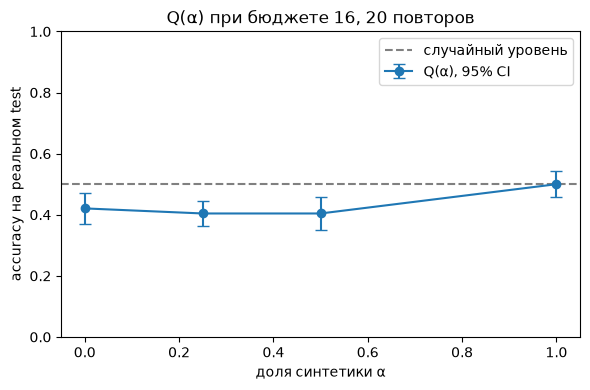

In [11]:
# Задание 10. Оценка всех моделей только на реальном test
test_feat = features['real_test']
test_rows = {r['id']: r for r in real_rows if r['split'] == 'test'}
assert set(test_feat['ids']) == set(test_rows) and all(r['origin'] == 'real' for r in test_rows.values()), 'test должен быть только реальным'
X_test, y_test, test_ids = test_feat['X'], test_feat['y'], test_feat['ids']
training_by_key = {r['model_key']: r for r in mixture_training}

predictions, model_scores = [], []
for key, clf in mixture_models.items():
    tr = training_by_key[key]
    assert not set(test_ids) & set(tr['train_ids_real']), f'{key}: test попал в train'
    pred = clf.predict(X_test)
    proba = clf.predict_proba(X_test)
    classes = clf.classes_.tolist()
    acc = float((pred == y_test).mean())
    model_scores.append({'model_key': key, 'alpha': tr['alpha'], 'repeat': tr['repeat'], 'accuracy': acc,
                         **{f'accuracy_class_{c}': float((pred[y_test == c] == c).mean()) for c in TARGET_CLASSES}})
    for i, image_id in enumerate(test_ids):
        r = test_rows[image_id]
        predictions.append({
            'model_key': key, 'alpha': tr['alpha'], 'repeat': tr['repeat'],
            'id': image_id, 'label': r['label'], 'image_url': r['image_url'],
            'y_true': int(y_test[i]), 'y_pred': int(pred[i]), 'correct': bool(pred[i] == y_test[i]),
            'proba': {str(c): round(float(p), 4) for c, p in zip(classes, proba[i])},
        })
assert len(predictions) == len(mixture_models) * len(test_ids)

def bootstrap_ci(values, n_boot=10_000, seed=SEED):
    """95% percentile-bootstrap CI среднего по повторам."""
    values = np.asarray(values)
    means = np.random.default_rng(seed).choice(values, size=(n_boot, len(values))).mean(axis=1)
    return [round(float(np.percentile(means, 2.5)), 4), round(float(np.percentile(means, 97.5)), 4)]

acc_by_alpha = {a: np.array([s['accuracy'] for s in sorted(model_scores, key=lambda s: s['repeat']) if s['alpha'] == a]) for a in ALPHAS}
baseline = acc_by_alpha[0.0]
by_alpha = {}
for a in ALPHAS:
    acc = acc_by_alpha[a]
    diff = acc - baseline                      # парное сравнение: тот же повтор, та же real-подвыборка
    by_alpha[f'{a:.2f}'] = {
        'n_real': int(round((1 - a) * TRAIN_BUDGET)), 'n_synthetic': int(round(a * TRAIN_BUDGET)),
        'n_models': len(acc),
        'accuracy_mean': round(float(acc.mean()), 4), 'accuracy_std': round(float(acc.std(ddof=1)), 4),
        'accuracy_min': round(float(acc.min()), 4), 'accuracy_max': round(float(acc.max()), 4),
        'accuracy_ci95': bootstrap_ci(acc),
        **{f'accuracy_class_{c}_mean': round(float(np.mean([s[f'accuracy_class_{c}'] for s in model_scores if s['alpha'] == a])), 4) for c in TARGET_CLASSES},
        'diff_vs_alpha0_mean': round(float(diff.mean()), 4),
        'diff_vs_alpha0_ci95': bootstrap_ci(diff) if a else [0.0, 0.0],
        'wins_ties_losses_vs_alpha0': [int((diff > 0).sum()), int((diff == 0).sum()), int((diff < 0).sum())],
    }

# Какие реальные фото трудны: доля моделей каждого α, ответивших верно
per_image = {image_id: {f'{a:.2f}': round(float(np.mean([p['correct'] for p in predictions if p['id'] == image_id and p['alpha'] == a])), 3)
                        for a in ALPHAS} for image_id in test_ids}

mixture_results = {
    'evaluation_set': {'name': 'PixMo-Count official test (real only)', 'n_images': len(test_ids),
                       'classes': {int(c): int((y_test == c).sum()) for c in TARGET_CLASSES}},
    'metric': 'accuracy на реальном test; среднее по повторам, 95% bootstrap CI',
    'chance_accuracy': round(float(max((y_test == c).mean() for c in TARGET_CLASSES)), 4),
    'accuracy_resolution': round(1 / len(test_ids), 4),   # шаг accuracy одной модели
    'config': {k: MIXTURE_CONFIG[k] for k in ('alphas', 'train_budget', 'n_repeats', 'target_classes', 'classifier')},
    'by_alpha': by_alpha,
    'per_model': model_scores,
    'per_image_accuracy': per_image,
}
save_json('mixture_results.json', mixture_results)
(ARTIFACTS/'predictions.jsonl').write_text(''.join(json.dumps(p, ensure_ascii=False) + '\n' for p in predictions), encoding='utf-8')

print(f"Реальный test: {len(test_ids)} фото, случайный уровень = {mixture_results['chance_accuracy']:.2f}\n")
print(f"{'α':>5} {'real':>4} {'syn':>4} {'Q(α) mean':>10} {'± std':>7} {'95% CI':>15} {'Δ vs α=0':>9} {'W/T/L':>9}")
for a, r in by_alpha.items():
    print(f"{a:>5} {r['n_real']:4d} {r['n_synthetic']:4d} {r['accuracy_mean']:10.3f} {r['accuracy_std']:7.3f} "
          f"{str(r['accuracy_ci95']):>15} {r['diff_vs_alpha0_mean']:+9.3f} {'/'.join(map(str, r['wins_ties_losses_vs_alpha0'])):>9}")

fig, ax = plt.subplots(figsize=(6, 4))
means = [by_alpha[f'{a:.2f}']['accuracy_mean'] for a in ALPHAS]
lo, hi = zip(*[by_alpha[f'{a:.2f}']['accuracy_ci95'] for a in ALPHAS])
ax.errorbar(ALPHAS, means, yerr=[np.subtract(means, lo), np.subtract(hi, means)], fmt='o-', capsize=4, label='Q(α), 95% CI')
ax.axhline(mixture_results['chance_accuracy'], ls='--', color='gray', label='случайный уровень')
ax.set_xlabel('доля синтетики α'); ax.set_ylabel('accuracy на реальном test'); ax.set_ylim(0, 1)
ax.set_title(f'Q(α) при бюджете {TRAIN_BUDGET}, {N_REPEATS} повторов'); ax.legend()
fig.tight_layout(); fig.savefig(ARTIFACTS/'mixture_q_alpha.png', dpi=120)
plt.show()

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

**Творческое мини-исследование**

- **Что делали**: скачали 40 новых реальных фото из PixMo-Count validation (20 + 20, test не трогали) и проверили гипотезы четырьмя зондами на признаках ResNet18 и той же VLM.
- **Зачем**: понять, в чём ограничение метода: в представлении, в переносе синтетика → реальность или в надёжности VLM-фильтра.
- **Результат**: `bonus.md`, `bonus_results.json`. Зонды: A (синтетика) 0.99, B (новые реальные) 0.78, C (синтетика → реальные) 0.50, D (real train → реальные) 0.55. H1 не подтверждается: сигнал о числе на реальных фото есть. VLM на реальных фото 0.90 против 100% на синтетике (H2 подтверждается); 2 из 4 ошибок — сбои генерации `!!!…`.

In [12]:
# Бонус. Творческое мини-исследование: переносится ли «число объектов» из синтетики в реальные фото
#
# Гипотеза (сформулирована из устройства метода, отложенный test для её выбора не используется):
#   H1. Замороженные признаки ResNet18 (ImageNet, global average pooling) линейно кодируют число объектов
#       в синтетическом домене (там число однозначно связано с площадью цветных пикселей), но не на реальных фото:
#       линейный классификатор 2 vs 3 на синтетике будет почти безошибочен, а на новых реальных фото — на уровне случая.
#   H2. VLM, подтвердившая синтетику со 100% согласием (задание 5), на реальных фото считает заметно хуже —
#       значит, согласие VLM на синтетике переоценивает её надёжность в реальном домене.
# Проверка — только на ДОПОЛНИТЕЛЬНЫХ реальных входах: новых фото из PixMo-Count validation,
# не пересекающихся ни с real train, ни с real test.
import urllib.request
from urllib.parse import urlencode
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from open_real_scenes import API

BONUS_DIR = DATA_DIR/'bonus'; BONUS_DIR.mkdir(parents=True, exist_ok=True)
EXTRA_MANIFEST = BONUS_DIR/'extra_real_manifest.jsonl'
N_EXTRA_PER_CLASS = 4 if FAST_DEV_RUN else 20
used_rows = {(r['source_split'], r['source_row']) for r in real_rows}
used_urls = {r['image_url'] for r in real_rows}
used_hashes = {r['pixel_sha256'] for r in real_rows}

def n_class(rows, c):
    return sum(r['answer'] == str(c) for r in rows)

def download_extra_real(per_class=N_EXTRA_PER_CLASS, source_split='validation', max_rows=540):
    """Новые реальные фото PixMo-Count validation с count ∈ {2, 3}, не использованные в основном эксперименте."""
    if EXTRA_MANIFEST.exists():
        rows = read_jsonl(EXTRA_MANIFEST)
        if all(n_class(rows, c) == per_class for c in TARGET_CLASSES) and all(Path(r['image']).is_file() for r in rows):
            return rows
    chosen = []
    for offset in range(0, max_rows, 100):
        query = urlencode(dict(dataset='allenai/pixmo-count', config='default', split=source_split,
                               offset=offset, length=min(100, max_rows - offset)))
        with urllib.request.urlopen(API + '?' + query, timeout=35) as response:
            entries = json.load(response)['rows']
        for entry in entries:
            r, idx = entry['row'], entry['row_idx']
            if r['count'] not in TARGET_CLASSES or (source_split, idx) in used_rows or r['image_url'] in used_urls:
                continue
            if n_class(chosen, r['count']) >= per_class:
                continue
            path = BONUS_DIR/f'pixmo-count-extra-{idx}.jpg'
            try:
                if not path.exists():
                    req = urllib.request.Request(r['image_url'], headers={'User-Agent': 'Mozilla/5.0 (educational research)'})
                    with urllib.request.urlopen(req, timeout=30) as response:
                        path.write_bytes(response.read())
                with Image.open(path) as image:
                    image.verify()
            except Exception:
                path.unlink(missing_ok=True)
                continue
            if pixel_sha256(path) in used_hashes:
                continue
            chosen.append({'id': f'pixmo-count-extra-{idx}', 'split': 'bonus_extra', 'origin': 'real',
                           'image': str(path.resolve()), 'answer': str(r['count']), 'label': r['label'],
                           'question': f"How many {r['label']} are visible? Answer with one integer.",
                           'source': 'https://huggingface.co/datasets/allenai/pixmo-count',
                           'source_split': source_split, 'source_row': idx, 'image_url': r['image_url'],
                           'downloaded_sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
                           'pixel_sha256': pixel_sha256(path)})
        if all(n_class(chosen, c) >= per_class for c in TARGET_CLASSES):
            break
    if any(n_class(chosen, c) < per_class for c in TARGET_CLASSES):
        raise RuntimeError(f'Недостаточно новых реальных фото: {len(chosen)}; повторите запуск или уменьшите N_EXTRA_PER_CLASS')
    EXTRA_MANIFEST.write_text(''.join(json.dumps(c, ensure_ascii=False) + '\n' for c in chosen), encoding='utf-8')
    return chosen

extra_rows = download_extra_real()
assert not {r['id'] for r in extra_rows} & {r['id'] for r in real_rows}
assert not {r['pixel_sha256'] for r in extra_rows} & used_hashes, 'дополнительные фото пересекаются с основным экспериментом'
X_extra = extract_features([r['image'] for r in extra_rows])
y_extra = np.array([int(r['answer']) for r in extra_rows])
print(f'Дополнительные реальные фото: {len(extra_rows)}, классы {dict(zip(*map(np.ndarray.tolist, np.unique(y_extra, return_counts=True))))}')

def wilson_ci(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return [round(float(c - h), 4), round(float(c + h), 4)]

def probe():
    # тот же классификатор, что в задании 9, без подбора гиперпараметров
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5_000, random_state=SEED))

def summarize(name, y_true, y_pred, note):
    k, n = int((y_true == y_pred).sum()), len(y_true)
    return {'probe': name, 'accuracy': round(k / n, 4), 'ci95_wilson': wilson_ci(k, n), 'n': n, 'note': note}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
probes = [
    # A. Кодируют ли признаки число объектов в синтетическом домене
    summarize('A: synthetic CV', syn_y, cross_val_predict(probe(), syn_X, syn_y, cv=cv),
              '5-fold CV на принятой синтетике, классы 2/3'),
    # B. Кодируют ли его на реальных фото при обучении в том же домене
    summarize('B: extra real CV', y_extra, cross_val_predict(probe(), X_extra, y_extra, cv=cv),
              '5-fold CV на дополнительных реальных фото'),
    # C. Перенос синтетика → реальность (аналог α = 1)
    summarize('C: synthetic → extra real', y_extra, probe().fit(syn_X, syn_y).predict(X_extra),
              f'обучение на {len(syn_y)} синтетических, тест на новых реальных'),
    # D. Реальные → реальные на независимых входах (аналог α = 0)
    summarize('D: real train → extra real', y_extra, probe().fit(real_train_feat['X'], real_train_feat['y']).predict(X_extra),
              f"обучение на {len(real_train_feat['y'])} real train, тест на новых реальных"),
]

# H2. Та же VLM и тот же шаблон вопроса на новых реальных фото (нужен GPU; подменять ответы нельзя)
vlm_extra = None
if torch.cuda.is_available():
    # `model` должен быть именно VLM (имя легко перезаписать другим объектом)
    if not hasattr(globals().get('model'), 'generate') or 'processor' not in globals():
        exec(VLM_LOADER)
    raw = []
    for start in range(0, len(extra_rows), BATCH_SIZE):
        batch = extra_rows[start:start + BATCH_SIZE]
        raw += infer_batch([r['image'] for r in batch], [r['question'] for r in batch])
    parsed = [parse_count(t) for t in raw]
    vlm_pred = np.array([-1 if p is None else p for p in parsed])
    for r, t, p in zip(extra_rows, raw, parsed):
        r['vlm_raw'], r['vlm_count'] = t, p
    vlm_extra = summarize('VLM on extra real', y_extra, vlm_pred, f'{MODEL_ID}, тот же шаблон вопроса, что и для синтетики')
    vlm_extra['parse_failures'] = sum(p is None for p in parsed)   # сбои генерации, а не ошибки счёта
    probes.append(vlm_extra)
else:
    print('GPU недоступен: проверка H2 пропущена.')
EXTRA_MANIFEST.write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in extra_rows), encoding='utf-8')

main = mixture_results['by_alpha']
vlm_syn_acc = json.loads((ARTIFACTS/'verification_summary.json').read_text(encoding='utf-8'))['vlm_accuracy']
bonus_results = {
    'hypotheses': {'H1': 'ResNet18 кодирует число объектов на синтетике, но не на реальных фото',
                   'H2': 'точность VLM на реальных фото ниже её согласия на синтетике'},
    'decision_rule': '«уровень случая» = 95% Wilson CI содержит 0.5',
    'extra_real': {'n': len(extra_rows), 'manifest': str(EXTRA_MANIFEST), 'source': 'PixMo-Count validation, неиспользованные строки'},
    'probes': probes,
    'main_experiment': {a: {'accuracy_mean': r['accuracy_mean'], 'ci95': r['accuracy_ci95']} for a, r in main.items()},
    'vlm_accuracy_on_synthetic': vlm_syn_acc,
}
save_json('bonus_results.json', bonus_results)

# Вердикт по заранее заданному правилу
res = {p['probe']: p for p in probes}
at_chance = lambda p: p['ci95_wilson'][0] <= 0.5 <= p['ci95_wilson'][1]
A, B, C, D = (res[k] for k in ('A: synthetic CV', 'B: extra real CV', 'C: synthetic → extra real', 'D: real train → extra real'))
if A['ci95_wilson'][0] > 0.5 and at_chance(B):
    h1_text = (f"**подтверждается**: на синтетике зонд разделяет 2 и 3 с точностью {A['accuracy']:.0%} (CI {A['ci95_wilson']}), "
               f"а на новых реальных фото — {B['accuracy']:.0%} (CI {B['ci95_wilson']}), что не отличается от случая.")
else:
    h1_text = (f"**не подтверждается** в заявленной форме: синтетика {A['accuracy']:.0%} (CI {A['ci95_wilson']}), "
               f"новые реальные {B['accuracy']:.0%} (CI {B['ci95_wilson']}).")
if vlm_extra is None:
    h2_text = 'не проверена: в этом запуске не было GPU для VLM.'
elif vlm_extra['ci95_wilson'][1] < vlm_syn_acc:
    h2_text = (f"**подтверждается**: на синтетике VLM согласна в {vlm_syn_acc:.0%} случаев, "
               f"на новых реальных фото точна в {vlm_extra['accuracy']:.0%} (CI {vlm_extra['ci95_wilson']}); "
               f"из них ответов без числа (сбой генерации): {vlm_extra['parse_failures']}.")
else:
    h2_text = (f"**не подтверждается**: на новых реальных фото VLM точна в {vlm_extra['accuracy']:.0%} "
               f"(CI {vlm_extra['ci95_wilson']}), что совместимо с {vlm_syn_acc:.0%} на синтетике.")
if at_chance(B) and at_chance(C) and at_chance(D):
    compare_text = ('Все зонды на реальных фото, как и Q(α), не отличаются от случая: замороженное представление не несёт '
                    'информации о числе объектов на реальных фото, и никакая доля синтетики в нём помочь не может.')
elif not at_chance(B) and at_chance(C) and at_chance(D):
    compare_text = (f"Зонд B ({B['accuracy']:.2f}) выше случая: при обучении на {len(y_extra) * 4 // 5} реальных фото того же распределения "
                    'признаки всё же разделяют 2 и 3. Значит, слабый Q(α) объясняется не только представлением, но и '
                    f"малым бюджетом ({TRAIN_BUDGET} примеров в задании 9, {len(real_train_feat['y'])} в зонде D) и разрывом доменов: "
                    'синтетика (зонд C) этот сигнал на реальных фото не воспроизводит.')
else:
    compare_text = ('Картина смешанная: часть зондов отличается от случая. Расхождения с Q(α) ожидаемы при 12 тестовых фото '
                    '(шаг accuracy 1/12) и 40 дополнительных; вывод стоит проверить на большем числе реальных входов.')

table = '\n'.join(f"| {p['probe']} | {p['accuracy']:.3f} | {p['ci95_wilson']} | {p['n']} | {p['note']} |" for p in probes)
main_table = '\n'.join(f"| α = {a} | {r['accuracy_mean']:.3f} | {r['accuracy_ci95']} |" for a, r in main.items())
bonus_md = f"""# Бонус: переносится ли «число объектов» из синтетики в реальные фото

## Гипотеза
- **H1.** Замороженные признаки ResNet18 (ImageNet, global average pooling) линейно кодируют число объектов в синтетическом домене, где число однозначно связано с площадью цветных пикселей, но не на реальных фото PixMo-Count: линейный классификатор 2 vs 3 на синтетике почти безошибочен, на новых реальных фото — на уровне случая.
- **H2.** VLM, согласная с рендерером на синтетике, на реальных фото считает заметно хуже, то есть фильтр VLM переоценивает свою надёжность в реальном домене.

Гипотезы выведены из устройства метода: глобальный pooling и обучение на ImageNet делают признаки инвариантными к числу экземпляров, а синтетические сцены однородны и просты. Отложенный real test для выбора гипотезы и настройки не использовался.

## Протокол
1. Скачаны {len(extra_rows)} **новых** реальных фото из PixMo-Count validation (по {N_EXTRA_PER_CLASS} с count = 2 и 3). Они не пересекаются с real train и real test по строке датасета, URL и хешу пикселей. Манифест: `{Path(os.path.relpath(EXTRA_MANIFEST)).as_posix()}`.
2. Признаки — тот же замороженный ResNet18 и тот же препроцессинг, что в задании 8.
3. Зонды — тот же классификатор (`StandardScaler → LogisticRegression(C=1)`), что в задании 9, без подбора гиперпараметров: A — 5-fold CV на синтетике; B — 5-fold CV на новых реальных; C — синтетика → новые реальные (аналог α = 1); D — real train → новые реальные (аналог α = 0).
4. H2: та же VLM и тот же шаблон вопроса, что в задании 5, на новых реальных фото.
5. Правило решения задано заранее: «уровень случая» = 95% Wilson CI содержит 0.5. Seed = {SEED}.

## Наблюдения
| Зонд | Accuracy | 95% CI | n | Описание |
|---|---|---|---|---|
{table}

Основной эксперимент (задание 10, отложенный real test, среднее по {N_REPEATS} повторам):

| Смесь | Q(α) | 95% CI |
|---|---|---|
{main_table}

Согласие VLM с рендерером на синтетике (задание 5): {vlm_syn_acc:.0%}.

## Вывод
- **H1** {h1_text}
- **H2** {h2_text}
- **Сопоставление с основным экспериментом.** Зонд D (аналог α = 0) даёт {D['accuracy']:.3f}, а Q(0) = {main['0.00']['accuracy_mean']:.3f}; зонд C (аналог α = 1) даёт {C['accuracy']:.3f}, а Q(1) = {main['1.00']['accuracy_mean']:.3f}. {compare_text}
- **Ограничения.** Малые выборки и широкие доверительные интервалы; только классы 2 и 3; одна архитектура признаков; синтетика без фона, текстур и окклюзий.

Машиночитаемые результаты: `bonus_results.json`.
"""
bonus_path = ARTIFACTS/'bonus.md'
bonus_path.write_text(bonus_md, encoding='utf-8')
print(table)
print(f'\nH1: {h1_text}\nH2: {h2_text}\n\nОтчёт: {bonus_path}')

Дополнительные реальные фото: 40, классы {2: 20, 3: 20}
| A: synthetic CV | 0.993 | [0.9617, 0.9988] | 144 | 5-fold CV на принятой синтетике, классы 2/3 |
| B: extra real CV | 0.775 | [0.625, 0.8768] | 40 | 5-fold CV на дополнительных реальных фото |
| C: synthetic → extra real | 0.500 | [0.352, 0.648] | 40 | обучение на 144 синтетических, тест на новых реальных |
| D: real train → extra real | 0.550 | [0.3983, 0.6929] | 40 | обучение на 24 real train, тест на новых реальных |
| VLM on extra real | 0.900 | [0.7695, 0.9604] | 40 | Qwen/Qwen2.5-VL-3B-Instruct, тот же шаблон вопроса, что и для синтетики |

H1: **не подтверждается** в заявленной форме: синтетика 99% (CI [0.9617, 0.9988]), новые реальные 78% (CI [0.625, 0.8768]).
H2: **подтверждается**: на синтетике VLM согласна в 100% случаев, на новых реальных фото точна в 90% (CI [0.7695, 0.9604]); из них ответов без числа (сбой генерации): 2.

Отчёт: artifacts\lab12\bonus.md


**Зонды бонусного исследования.** Все четыре — один и тот же классификатор (`StandardScaler → LogisticRegression`) на тех же признаках ResNet18; различаются только данные для обучения и проверки.

| Зонд | Учится на | Проверяется на | Вопрос |
|---|---|---|---|
| **A** | синтетике | другой синтетике (5-fold CV) | Различают ли признаки 2 и 3 фигуры на нарисованных картинках? |
| **B** | новых реальных фото | других новых реальных фото (5-fold CV) | Различают ли они 2 и 3 объекта на реальных фото? |
| **C** | синтетике | новых реальных фото | Переносится ли выученное на фигурах на реальные объекты (аналог α = 1)? |
| **D** | real train (24 фото) | новых реальных фото | Повторяется ли основной результат (α = 0) на независимых фото? |

**Как читать результат.** Случайный уровень — 0.5; зонд «на уровне случая», если его 95% CI содержит 0.5.

- **A высокий, B ≈ 0.5** → H1 подтверждается: признаки кодируют число только на простой синтетике. Тогда слабый Q(α) объясняется представлением, а не долей синтетики.
- **B заметно выше 0.5** → информация о числе на реальных фото в признаках есть; слабый Q(α) скорее связан с малым бюджетом (16 примеров) и маленьким тестом (12 фото).
- **A ≈ 0.5** → признаки не кодируют число даже на синтетике; метод не работает уже в исходном домене.
- **C ≈ 0.5 при D > 0.5** → синтетика не переносится на реальные фото; **C и D оба ≈ 0.5** → совпадает с основным экспериментом.
- **VLM на реальных фото заметно ниже её 100% на синтетике** → H2 подтверждается: фильтр VLM на синтетике не гарантирует качества на реальных данных.

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

Реальный test: 12 фото {'2': 6, '3': 6}, случайный уровень 0.5, шаг accuracy одной модели 0.0833

    α   Q(α)           95% CI  acc «2»  acc «3»  доля ответов «3»
 0.00  0.421 [0.3708, 0.4708]    0.667    0.175             0.254
 0.25  0.404 [0.3625, 0.4458]    0.542    0.267             0.362
 0.50  0.404   [0.35, 0.4583]    0.417    0.392             0.487
 1.00  0.500 [0.4583, 0.5417]    0.242    0.758             0.758

фото                   объект     ответ α=0.00 α=0.25 α=0.50 α=1.00
pixmo-count-test-12    dogs           3   0.00   0.15   0.35   0.90
pixmo-count-test-15    ducks          3   0.00   0.05   0.10   0.60
pixmo-count-test-23    people         3   0.00   0.10   0.20   0.60
pixmo-count-test-20    dogs           3   0.05   0.25   0.55   1.00
pixmo-count-test-24    people         3   0.20   0.35   0.60   0.70
pixmo-count-test-60    airplanes      2   0.40   0.30   0.30   0.45
pixmo-count-test-62    people         2   0.45   0.45   0.40   0.10
pixmo-count-test-65    peop

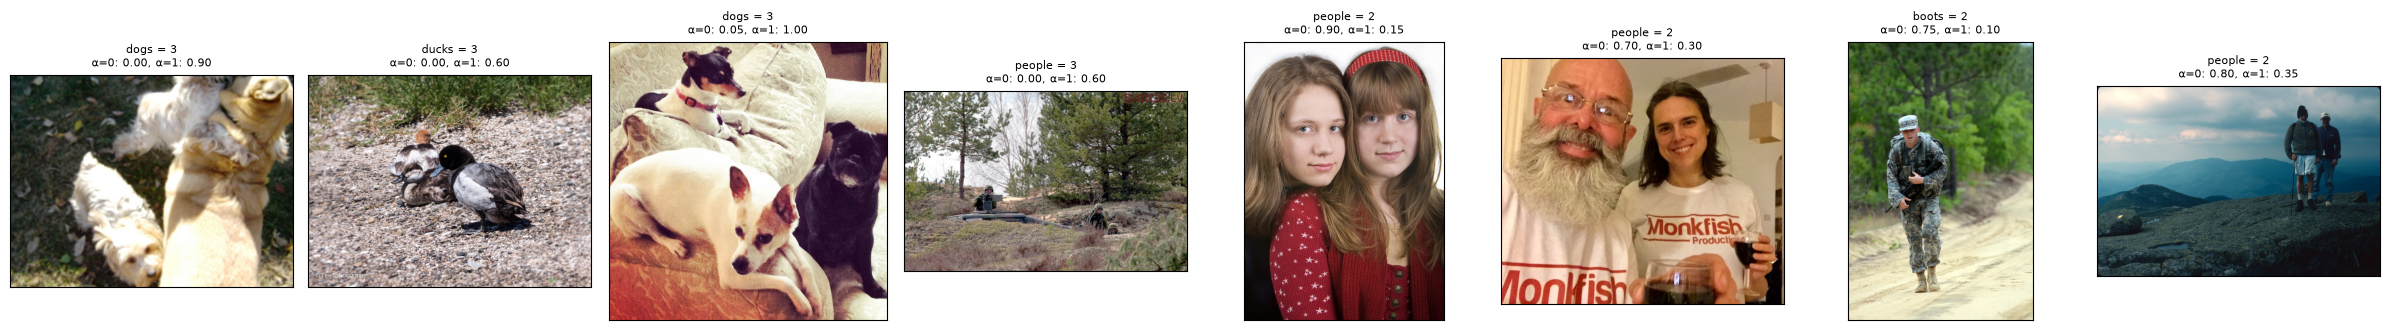

In [13]:
# Анализ результатов: показатели на фиксированном реальном test и разбор ошибок по сохранённым предсказаниям
assert not FAST_DEV_RUN, 'FAST_DEV_RUN не является основанием для итогового вывода: запустите полный режим'
results = json.loads((ARTIFACTS/'mixture_results.json').read_text(encoding='utf-8'))
preds = read_jsonl(ARTIFACTS/'predictions.jsonl')
test_meta = {r['id']: r for r in read_jsonl(ARTIFACTS/'real_manifest.jsonl') if r['split'] == 'test'}
alphas = list(results['by_alpha'])

# 1. Q(α) и смещение предсказаний: какую долю тестовых фото модели относят к классу 3
print(f"Реальный test: {results['evaluation_set']['n_images']} фото {results['evaluation_set']['classes']}, "
      f"случайный уровень {results['chance_accuracy']}, шаг accuracy одной модели {results['accuracy_resolution']}\n")
print(f"{'α':>5} {'Q(α)':>6} {'95% CI':>16} {'acc «2»':>8} {'acc «3»':>8} {'доля ответов «3»':>17}")
bias = {}
for a in alphas:
    r = results['by_alpha'][a]
    bias[a] = float(np.mean([p['y_pred'] == 3 for p in preds if f"{p['alpha']:.2f}" == a]))
    print(f"{a:>5} {r['accuracy_mean']:6.3f} {str(r['accuracy_ci95']):>16} {r['accuracy_class_2_mean']:8.3f} "
          f"{r['accuracy_class_3_mean']:8.3f} {bias[a]:17.3f}")

# 2. Разбор по фото: доля моделей каждого α, ответивших верно
per_image = results['per_image_accuracy']
print(f"\n{'фото':22s} {'объект':10s} {'ответ':>5} " + ' '.join(f'α={a:>4}' for a in alphas))
for image_id, accs in sorted(per_image.items(), key=lambda kv: kv[1][alphas[0]]):
    m = test_meta[image_id]
    print(f"{image_id:22s} {m['label'][:10]:10s} {m['answer']:>5} " + ' '.join(f'{accs[a]:6.2f}' for a in alphas))

always_wrong_a0 = [i for i, accs in per_image.items() if accs[alphas[0]] <= 0.1]
flipped = [i for i, accs in per_image.items() if accs[alphas[0]] >= 0.7 and accs[alphas[-1]] <= 0.35]
error_analysis = {
    'bias_share_pred_3': bias,
    'hard_for_real_only (acc α=0 ≤ 0.1)': {i: {'label': test_meta[i]['label'], 'answer': test_meta[i]['answer']} for i in always_wrong_a0},
    'broken_by_synthetic (acc α=0 ≥ 0.7, α=1 ≤ 0.35)': {i: {'label': test_meta[i]['label'], 'answer': test_meta[i]['answer']} for i in flipped},
    'test_labels': {i: m['label'] for i, m in test_meta.items()},
}
save_json('error_analysis.json', error_analysis)
print('\nПочти всегда ошибочны при α=0:', [(i, test_meta[i]['label'], test_meta[i]['answer']) for i in always_wrong_a0])
print('Верны при α=0, но ломаются при α=1:', [(i, test_meta[i]['label'], test_meta[i]['answer']) for i in flipped])

# 3. Сами трудные фото: что видит модель
show = always_wrong_a0 + flipped
fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.4))
for ax, image_id in zip(np.atleast_1d(axes), show):
    m = test_meta[image_id]
    ax.imshow(Image.open(m['image']).convert('RGB')); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{m['label']} = {m['answer']}\nα=0: {per_image[image_id][alphas[0]]:.2f}, α=1: {per_image[image_id][alphas[-1]]:.2f}", fontsize=8)
fig.tight_layout(); fig.savefig(ARTIFACTS/'error_cases.png', dpi=110)
plt.show()

### Выводы по результатам полного прогона

**Q(α) на фиксированном отложенном test** (12 реальных фото PixMo-Count, по 6 с ответами 2 и 3; среднее по 20 повторам, бюджет train = 16):

| α | real / syn | Q(α) | 95% CI | acc «2» | acc «3» | доля ответов «3» |
|---|---|---|---|---|---|---|
| 0.00 | 16 / 0 | 0.421 | [0.37; 0.47] | 0.67 | 0.18 | 0.25 |
| 0.25 | 12 / 4 | 0.404 | [0.36; 0.45] | 0.54 | 0.27 | 0.36 |
| 0.50 | 8 / 8 | 0.404 | [0.35; 0.46] | 0.42 | 0.39 | 0.49 |
| 1.00 | 0 / 16 | 0.500 | [0.46; 0.54] | 0.24 | 0.76 | 0.76 |

- **Ни одна смесь не лучше случайного уровня 0.5.** При α = 0 качество даже ниже случая: CI [0.37; 0.47] не содержит 0.5.
- **Рост при α = 1 — не умение считать.** Формально α = 1 лучше α = 0: Δ = +0.08, CI [0.03; 0.13], 11 побед / 7 ничьих / 2 поражения. Но модели на чистой синтетике отвечают «3» на 76% фото: точность на тройках 0.76, на двойках — 0.24. Accuracy 0.50 получается из этого смещения, а не из счёта.
- **Синтетика сдвигает порог решения, а не добавляет сигнал.** Доля ответов «3» растёт монотонно с α: 0.25 → 0.36 → 0.49 → 0.76, а общая точность почти не меняется. Возможное (непроверенное) объяснение: загромождённые реальные фото в пространстве признаков ближе к синтетическим сценам с бо́льшей закрашенной площадью, то есть с 3 фигурами.

**Разбор ошибок** по `predictions.jsonl` (подробности — `error_analysis.json`, картинки — `error_cases.png`):
- **При α = 0 почти всегда ошибочны 4 фото с ответом 3:** `test-12` и `test-20` (dogs), `test-15` (ducks), `test-23` (people). В real train обе фотографии собак имеют count = 2, а уток нет вовсе. Модель выучила ярлык «категория объекта → число» вместо счёта (shortcut): глобальные признаки ResNet18 прежде всего кодируют *что* изображено.
- **При α = 1 ломаются фото с ответом 2:** `test-58`, `test-65`, `test-81` (people) и `test-74` (boots). Это прямое следствие смещения к «3».
- **`test-60` (airplanes, 2) трудно при любом α** (≤ 0.45).

**Бонус** (40 новых реальных фото из validation, test не использовался): зонд A (синтетика) — 0.99, B (реальные, 5-fold CV) — 0.78, C (синтетика → реальные) — 0.50, D (real train → реальные) — 0.55, VLM — 0.90.
- **Сигнал о числе на реальных фото в признаках есть.** Зонд B выше случая при обучении на 32 фото того же распределения. Значит, провал основного эксперимента связан не только с представлением, но и с малым бюджетом (16 примеров) и несовпадением категорий между train и test. Оговорка: B тоже может отчасти пользоваться категориальными корреляциями.
- **Синтетика на реальные фото не переносится** (C = 0.50).
- **VLM на реальных фото менее надёжна, чем на синтетике:** 90% против 100%. Но 2 из 4 ошибок — сбои генерации (ответ `!!!…`), а не ошибки счёта: собственно счёт верен в 36 из 38 случаев.

**Ограничения выборки**
- **Test всего 12 фото, шаг accuracy 0.083.** Доверительные интервалы по 20 повторам отражают разброс обучающих подвыборок, но не неопределённость самого test: все модели видят одни и те же 12 фото. Для одной модели с 6/12 Wilson CI — [0.25; 0.75].
- **Состав данных узкий.** Только классы 2 и 3; 7 из 12 тестовых фото — people; категории train и test почти не пересекаются (ducks и boots в train отсутствуют).
- **Контрольные суммы.** У 32 из 36 файлов SHA256 не совпал с PixMo, потому что Flickr отдаёт заново закодированный JPEG. Метки относятся к тем же URL; расхождение зафиксировано в манифесте.
- **Синтетика проста:** однородные сцены, белый фон, 3 формы. VLM-фильтр ничего не отсеял (216 / 216), 2 пары почти-дублей по эмбеддингам (cos > 0.99) оставлены в данных.
- **Это перенос счёта между доменами**, а не распознавание геометрических фигур на фото. Вывод о пользе синтетики для in-domain подсчёта фигур по этому тесту не делается.

**Итог.** В данной постановке (замороженный ResNet18 + логистическая регрессия, бюджет 16) синтетические геометрические сцены не улучшают подсчёт объектов на реальных фото: Q(α) ≤ 0.5 при всех α, а кажущийся выигрыш при α = 1 объясняется смещением к классу 3. Числа в этом разделе взяты из полного прогона (`FAST_DEV_RUN = False`); при перезапуске сверяйте их с выводом ячейки выше и с `mixture_results.json`.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.

In [14]:
# Требования к сдаче: конфигурация, версии зависимостей, ресурсы и контрольные суммы артефактов
import importlib.metadata as metadata

REQUIRED_ARTIFACTS = ['synthetic_manifest.jsonl', 'verification.jsonl', 'accepted.jsonl', 'mixture_results.json', 'predictions.jsonl']
missing = [name for name in REQUIRED_ARTIFACTS if not (ARTIFACTS/name).is_file()]
if missing:
    raise FileNotFoundError(f'Нет обязательных артефактов: {missing}. Запустите ноутбук целиком в полном режиме.')
assert not FAST_DEV_RUN, 'Для сдачи нужен полный режим (FAST_DEV_RUN = False)'

def package_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

verification_rows = read_jsonl(ARTIFACTS/'verification.jsonl')

def vlm_seconds(rows, batch_size=BATCH_SIZE):
    """Строки одного батча идут подряд и делят batch_seconds: суммируем по одному разу на батч."""
    total, run, prev = 0.0, 0, None
    for r in rows:
        if r['batch_seconds'] != prev or run == batch_size:
            total, run, prev = total + r['batch_seconds'], 0, r['batch_seconds']
        run += 1
    return round(total, 1)

run_info = {
    'created_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'fast_dev_run': FAST_DEV_RUN,
    'seed': SEED,
    'python': platform.python_version(), 'platform': platform.platform(),
    'packages': {p: package_version(p) for p in ['torch', 'torchvision', 'transformers', 'accelerate', 'bitsandbytes',
                                                 'scikit-learn', 'pillow', 'numpy', 'matplotlib', 'joblib']},
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'resources': {
        'notebook_wall_seconds': round(time.time() - NOTEBOOK_T0, 1) if 'NOTEBOOK_T0' in globals() else None,
        'vlm_inference_seconds': vlm_seconds(verification_rows),
        'gpu_peak_memory_gib': round(torch.cuda.max_memory_allocated() / 2**30, 2) if torch.cuda.is_available() else None,
    },
    'config': {
        'renderer': json.loads((ARTIFACTS/'renderer_config.json').read_text(encoding='utf-8')),
        'scene_space': {'counts': COUNTS, 'layouts_per_combo': LAYOUTS_PER_COMBO, 'n_scenes': len(scene_specs)},
        'vlm': {'model_id': verification_rows[0]['model_id'], 'quantization': verification_rows[0]['quantization'],
                'generation': verification_rows[0]['generation'], 'question_template': 'How many {color} {shape}s are visible? Answer with one integer.'},
        'real_data': {'source': 'allenai/pixmo-count', 'train': 'validation', 'test': 'test',
                      'sizes': {'train': REAL_TRAIN_SIZE, 'test': REAL_TEST_SIZE}, 'license': 'ODC-BY-1.0; image rights may differ'},
        'features': {'backbone': 'resnet18', 'weights': str(WEIGHTS), 'frozen': True},
        'mixtures': MIXTURE_CONFIG,
    },
    'artifacts': {f.name: {'bytes': f.stat().st_size, 'sha256': hashlib.sha256(f.read_bytes()).hexdigest()}
                  for f in sorted(ARTIFACTS.iterdir()) if f.is_file() and f.name != 'run_info.json'},
}
save_json('run_info.json', run_info)
print(json.dumps({k: run_info[k] for k in ('packages', 'gpu', 'resources')}, ensure_ascii=False, indent=2))
print(f"Артефактов: {len(run_info['artifacts'])}; обязательные на месте: {REQUIRED_ARTIFACTS}")

{
  "packages": {
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "transformers": "5.17.0",
    "accelerate": "1.15.0",
    "bitsandbytes": "0.50.2",
    "scikit-learn": "1.9.1",
    "pillow": "12.3.0",
    "numpy": "2.5.3",
    "matplotlib": "3.11.2",
    "joblib": "1.6.0"
  },
  "gpu": "NVIDIA GeForce RTX 3060",
  "resources": {
    "notebook_wall_seconds": 754.2,
    "vlm_inference_seconds": 19.3,
    "gpu_peak_memory_gib": 9.48
  }
}
Артефактов: 26; обязательные на месте: ['synthetic_manifest.jsonl', 'verification.jsonl', 'accepted.jsonl', 'mixture_results.json', 'predictions.jsonl']


### Инструкция повторного запуска

1. **Окружение.**
   - Python 3.12 и GPU с CUDA (проверено на NVIDIA RTX 3060). Точные версии пакетов записаны в `artifacts/lab12/run_info.json`.
   - Установка: `pip install torch torchvision "transformers>=4.51" accelerate bitsandbytes scikit-learn pillow numpy matplotlib joblib`. Комментарий в `VLM_LOADER` рекомендует `transformers<5`; этот прогон выполнен на transformers 5.x.
2. **Входы.**
   - В корне проекта должен лежать `open_real_scenes.py`.
   - Нужен интернет: HF datasets-server для PixMo-Count и Flickr для самих фото.
   - Фото не коммитить: `data/` — в `.gitignore`.
3. **Запуск.**
   - В ячейке настройки оставить `FAST_DEV_RUN = False`.
   - Выполнить **Restart & Run All**: ячейки зависят друг от друга, и порядок важен.
   - Без GPU ноутбук остановится на ячейке VLM с явной ошибкой.
4. **Пути и переменные окружения.**
   - По умолчанию артефакты пишутся в `artifacts/lab12/`, данные — в `data/lab12/`.
   - Пути переопределяются через `CV_ARTIFACTS` и `CV_DATA`, модель VLM — через `CV_VLM_MODEL`, размер батча VLM — через `CV_VLM_BATCH`.
5. **Кэш.**
   - Уже скачанные реальные фото (`real_manifest.jsonl`, `bonus/extra_real_manifest.jsonl`) и полученные ответы VLM (`verification.jsonl`) переиспользуются.
   - Для полного пересчёта удалите `data/lab12/` и `artifacts/lab12/`.
6. **Проверка воспроизводимости.**
   - `specs_sha256` в `scene_specs_summary.json` должен быть равен `68bd72b8a36f2175d9217bbf911d1f9d5dbb100712fb8d494b21baa4ce999406`.
   - Задание 4 заново рендерит каждую сцену и сверяет её с сохранённой картинкой.
   - `run_info.json` содержит sha256 всех артефактов.
7. **Что сдавать.**
   - Папку `artifacts/lab12/`. Обязательные артефакты: `synthetic_manifest.jsonl`, `verification.jsonl`, `accepted.jsonl`, `mixture_results.json`, `predictions.jsonl`.
   - Плюс `run_info.json`, `bonus.md` и сам ноутбук с выводами ячеек.